## Домашка 2
<h4><em>«Одно Кольцо, чтоб править всеми,<br>
Одно Кольцо, чтоб всех найти,<br>
Одно Кольцо, чтоб собрать всех в тени<br>
И заковать их всех во Тьме»</em><br>
— <em>Властелин колец</em>
</h4>

Эта домашка про приоритизацию метрик. За неё можно получить максимум 12 баллов. 

**Дедлайны**   
Мягкий дедлайн: 27.09.2026 23:59 по МСК.   
Жесткий дедлайн: 04.10.2026 23:59 по МСК.

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.
После жесткого дедлайна работы не принимаются.

**Правила сдачи**  
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.

**Использование ИИ**

- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_2). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.

Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_2_data.zip)

In [2]:
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

### Warm up

#### 1. Game dev — 2 балла
У вас есть данные о событиях в мобильной игре. Рассчитайте и визуализируйте:
- User Stickiness — отношение DAU к MAU (MAU рассчитывайте скользящим окном 30 дней для каждой даты только для полного окна)
- ARPDAU
- Paying Share — доля платящих пользователей
- Sessions per User — среднее число сессий на пользователя
- Daily Play Time — среднее время, проводимое пользователем в игре в день (рассчитываем как общее время в приложении)
- Avg Attempts per Session — среднее число попыток на сессию

*Смотрим на подневную динамику

In [5]:
df_game = pd.read_csv('hw_2_gamedev.csv', index_col=0)
df_game.head()

,session_id,user,date,revenue,attempts,session_length_sec
0,24590322,k0xevcHJ,2022-11-02,NaN,2.0,263
1,24590323,fMaLiagr,2022-11-02,NaN,10.0,953
2,24590324,0EXv0Q2V,2022-11-02,NaN,6.0,630
3,24590325,nY32SwuK,2022-11-02,NaN,9.0,1262
4,24590326,3KZkImTN,2022-11-02,NaN,16.0,2871


Описание данных (уникальный ключ session_id)

- session_id — уникальный идентификатор сессии
- user — уникальный идентификатор юзера
- date — дата 
- revenue — суммарная выручка на сессию
- attempts — число попыток на сессию
- session_length_sec — длина сессии в секундах

In [36]:
df_game.describe()

,session_id,date,revenue,attempts,session_length_sec
count,3.151378e+06,3151378,99866.000000,2.960048e+06,3.151378e+06
mean,2.616601e+07,2022-11-25 03:56:56.071318784,6.357798,2.753213e+01,3.109896e+03
min,2.459032e+07,2022-11-02 00:00:00,0.990000,1.000000e+00,2.000000e+00
25%,2.537817e+07,2022-11-08 00:00:00,1.980000,6.000000e+00,4.990000e+02
50%,2.616601e+07,2022-11-21 00:00:00,2.990000,1.500000e+01,1.505000e+03
75%,2.695385e+07,2022-12-10 00:00:00,6.990000,3.400000e+01,3.828000e+03
max,2.774170e+07,2023-01-05 00:00:00,9701.213976,1.512913e+03,2.952370e+05
std,9.097246e+05,NaN,82.967460,4.524357e+01,5.560150e+03


In [31]:
df_game['date'] = pd.to_datetime(df_game['date'])

0         2022-11-02
1         2022-11-02
2         2022-11-02
3         2022-11-02
4         2022-11-02
             ...    
3151373   2023-01-05
3151374   2023-01-05
3151375   2023-01-05
3151376   2023-01-05
3151377   2023-01-05
Name: date, Length: 3151378, dtype: datetime64[ns]

In [3]:
def get_line_plot(df, x, y, title, annotate=False, vline=None):
    fig, ax1 = plt.subplots(figsize=(12,6))
    
    if len(y) == 2:
        ax1.plot(df[x], df[y[0]], label=y[0], color='blue')
        ax1.set_ylabel(y[0])

        plt.xticks(rotation=45)

        if annotate:
            for i, val in enumerate(df[y[0]]):
                ax1.text(df[x].iloc[i], val, f'{val:.2f}', fontsize=9)

        ax2 = ax1.twinx()
        ax2.plot(df[x], df[y[1]], label=y[1], color='green')
        ax2.set_ylabel(f'{y[1]}')
        ax2.tick_params(axis='y')

        if annotate:
            for i, val in enumerate(df[y[1]]):
                ax2.text(df[x].iloc[i], val, f'{val:.2f}', fontsize=9)

        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2,
                   loc='center left', bbox_to_anchor=(1.05, 0.8))

        ax1.grid(True, which='both')
        if vline is not None:
            ax1.axvline(vline, ls='--', color='grey')
        fig.suptitle(title)
        fig.tight_layout()
        
        return plt.show()

    else:
        for col in y:
            plt.plot(df[x], df[col], label=col, color='blue')

            if annotate:
                for i, val in enumerate(df[col]):
                    plt.text(df[x].iloc[i], val, f'{val:.2f}', fontsize=9)

        plt.title(title)
        plt.xlabel('Date')
        plt.ylabel('Metric Value')
        plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.8))
        plt.grid(True)
        if vline is not None:
            plt.axvline(vline, ls='--', color='grey')
        plt.xticks(rotation=45)
        plt.tight_layout()

    return plt.show()

In [4]:
def get_several_lines_plot(df, x, y_list, title, vline=None):
    plt.figure(figsize=(12,6))
    colors = ['green', 'blue', 'orange', 'pink', 'violet']
    
    for i, col in enumerate(y_list):
        if x == 'date':
            x_axis = df[x]
        else:
            x_axis = df[x].astype(str)

        y_axis = df[col]
        plt.plot(x_axis, y_axis, label=col, color=colors[i])

        for xi, yi in zip(x_axis, y_axis):
            if pd.notna(yi):
                plt.text(xi, yi, f'{yi:.2f}', fontsize=9, ha='center', va='bottom')

    plt.title(title)
    plt.xlabel('Date')
    plt.xticks(rotation=45)
    plt.ylabel('Metric Value')
    
    plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.9))
    
    plt.grid(True)
    if vline is not None:
        plt.axvline(vline, ls='--', color='grey')
    plt.tight_layout()
    plt.show()

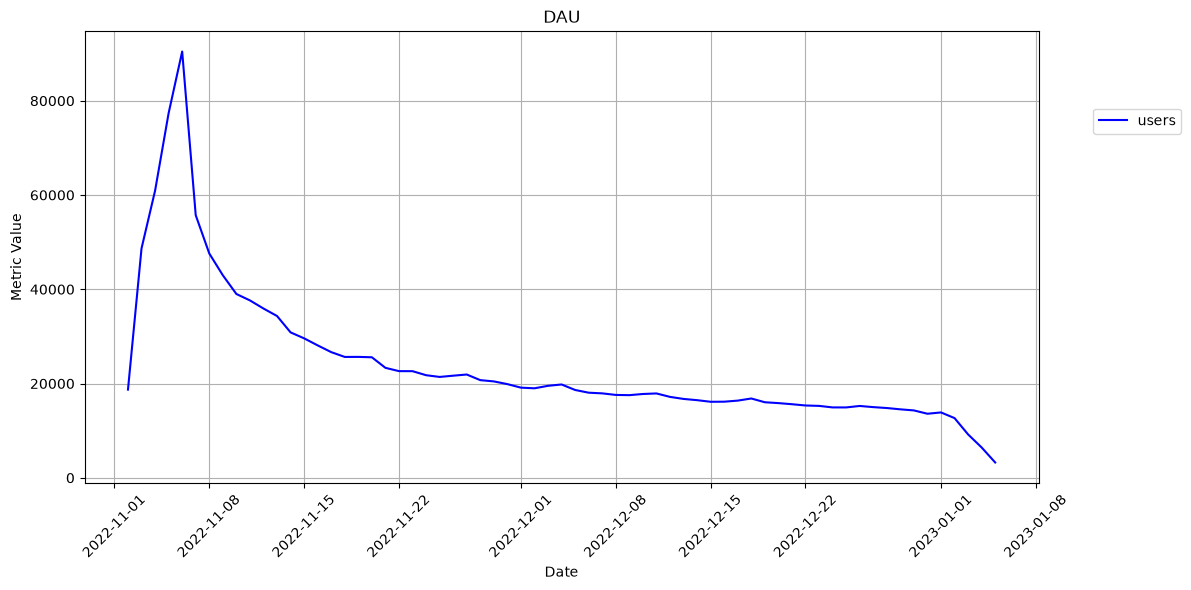

In [74]:
daily_users = df_game.groupby(['date'])['user'].nunique()
df_dau = pd.DataFrame({
    'date': daily_users.index,
    'users': daily_users.values
})
get_line_plot(df_dau, 'date', ['users'], title = 'DAU')


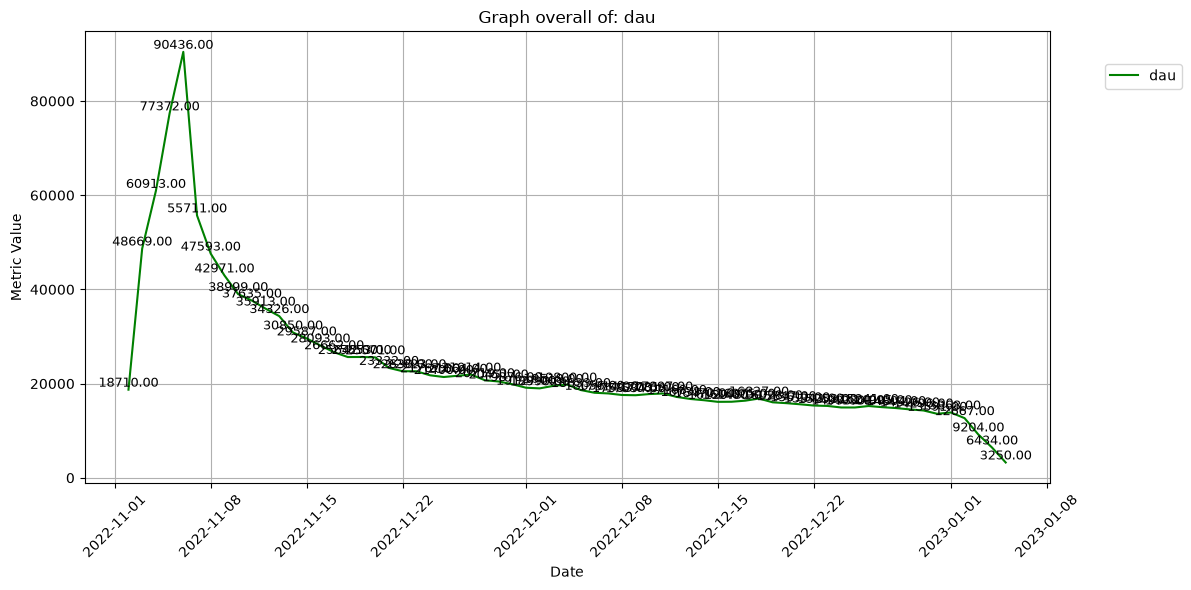

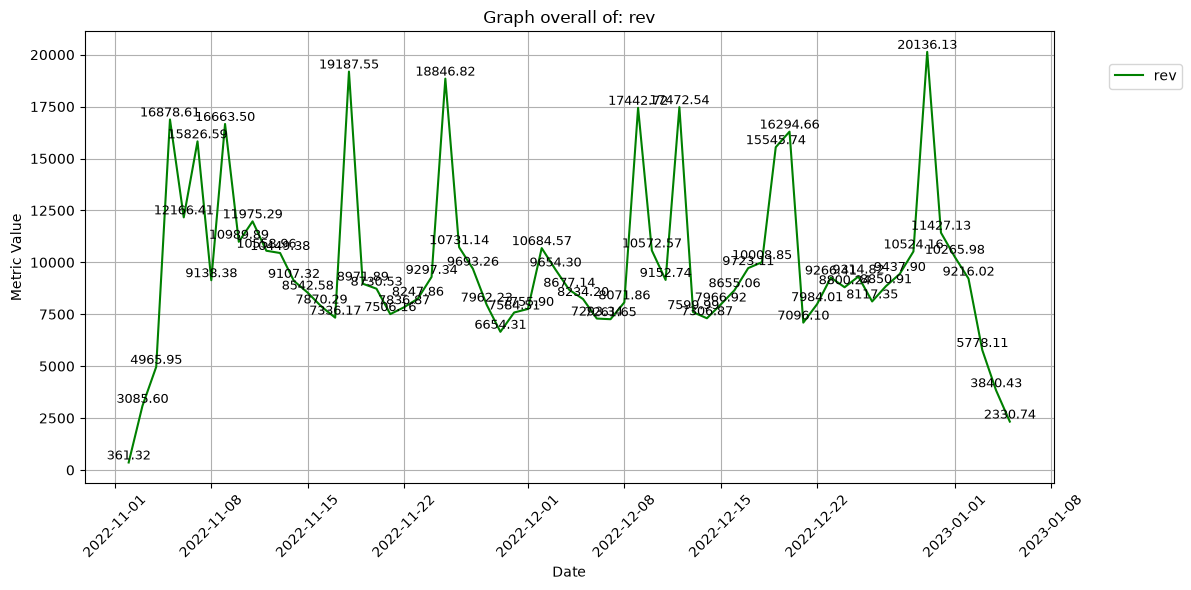

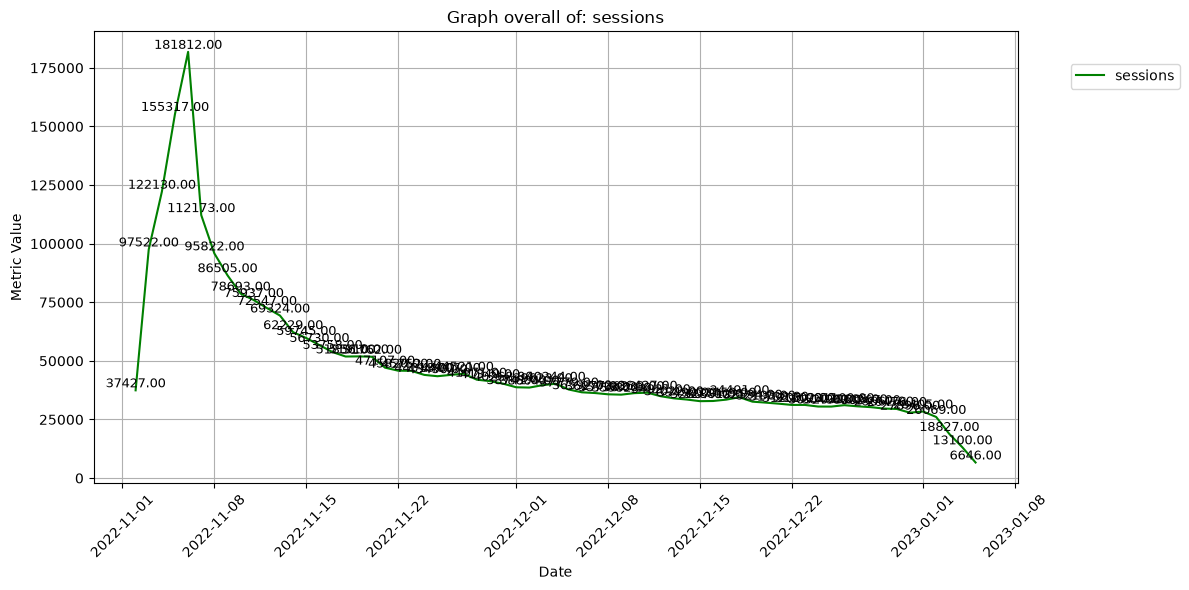

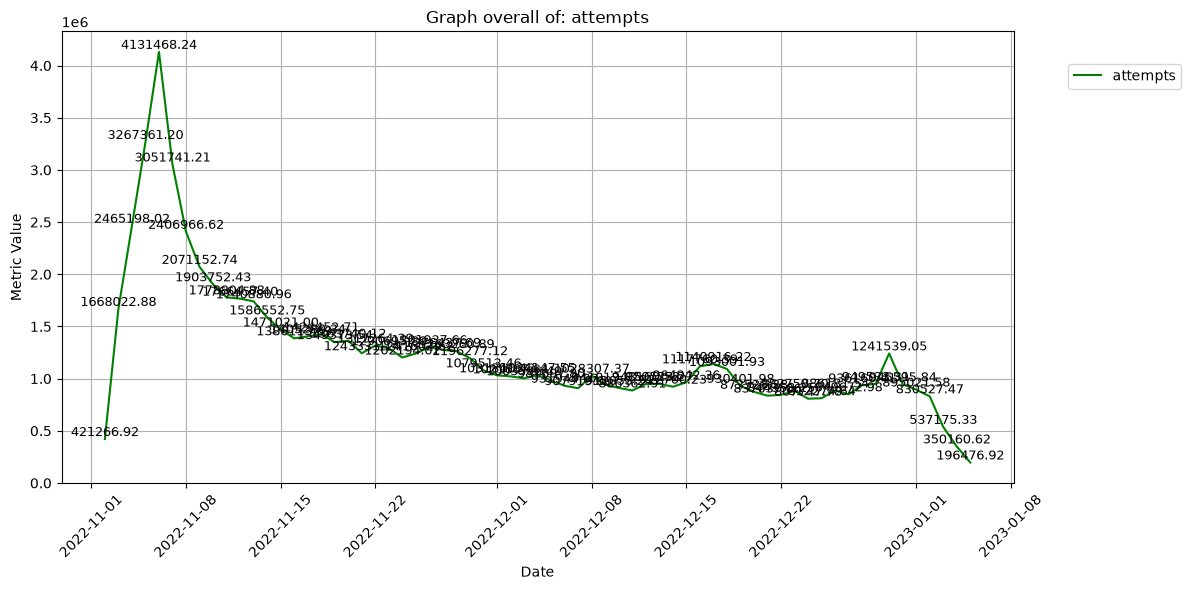

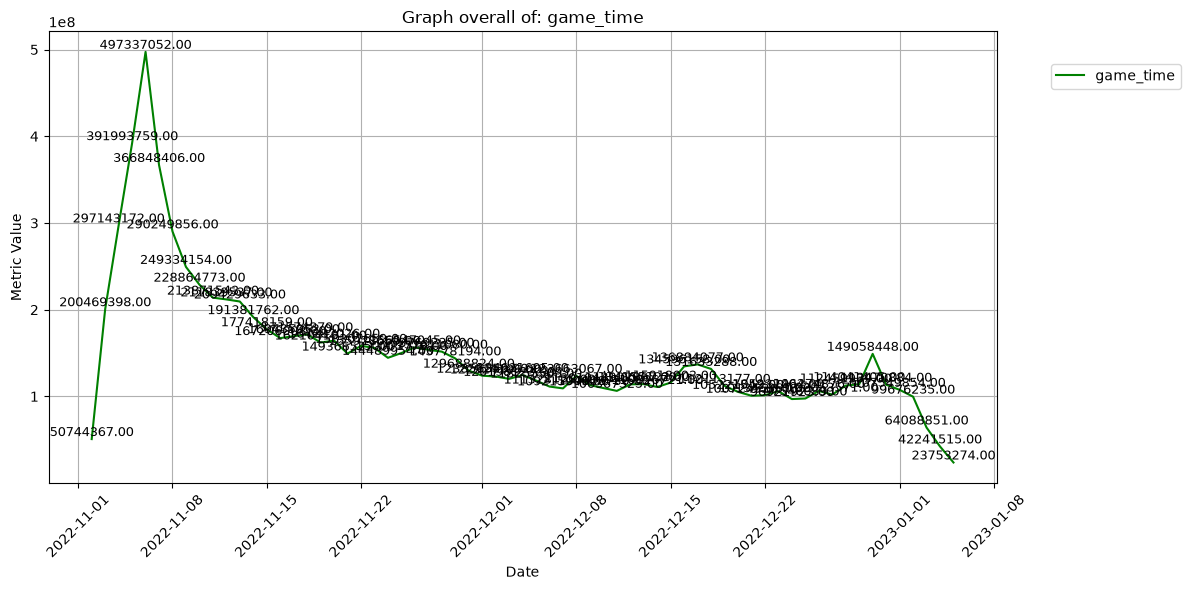

In [157]:
daily = df_game.groupby('date').agg(
    dau=('user', 'nunique'),
    rev=('revenue', 'sum'),
    sessions=('session_id', 'count'),
    attempts=('attempts', 'sum'),
    game_time=('session_length_sec', 'sum')
).reset_index()
plots = ['dau', 'rev', 'sessions', 'attempts', 'game_time']
for plot in plots:
    get_several_lines_plot(daily, 'date', [plot], title = f'Graph overall of: {plot}')

In [155]:
daily.date.min()

Timestamp('2022-11-02 00:00:00')

In [163]:
first_date = daily.date.min()
mau = {}
for d in daily.date:
    start = d - timedelta(days=29)
    if start < first_date:
        continue
    mask = (df_game['date'] >= start) & (df_game['date'] <= d)
    mau[d] = df_game[mask]['user'].nunique()
daily['mau'] = daily['date'].map(mau)

In [164]:
daily

,date,dau,rev,sessions,attempts,game_time,mau
0,2022-11-02,18710,361.319997,37427,4.212669e+05,50744367,NaN
1,2022-11-03,48669,3085.599963,97522,1.668023e+06,200469398,NaN
2,2022-11-04,60913,4965.949919,122130,2.465198e+06,297143172,NaN
3,2022-11-05,77372,16878.611168,155317,3.267361e+06,391993759,NaN
4,2022-11-06,90436,12166.409799,181812,4.131468e+06,497337052,NaN
...,...,...,...,...,...,...,...
60,2023-01-01,13868,10265.979854,28405,8.950216e+05,107549854,54833.0
61,2023-01-02,12667,9216.019871,26069,8.305275e+05,99676235,54001.0
62,2023-01-03,9204,5778.109929,18827,5.371753e+05,64088851,52973.0
63,2023-01-04,6434,3840.429948,13100,3.501606e+05,42241515,52163.0


In [213]:
daily['payers'] = df_game[df_game['revenue'] > 0].groupby('date')['user'].nunique().values

In [10]:
import numpy as np
import pandas as pd

In [217]:
daily['stickiness'] = daily['dau'] / daily['mau']
daily['arpdau'] = daily['rev'] / daily['dau']
daily['paying_share'] = daily['payers'] / daily['dau']
daily['sessions_per_user'] = daily['sessions'] / daily['dau']
daily['play_time_min'] = daily['game_time'] / daily['dau'] / 60
daily['attempts_per_session'] = daily['attempts'] / daily['sessions']

In [219]:
daily

,date,dau,rev,sessions,attempts,game_time,mau,stickiness,arpdau,sessions_per_user,play_time_min,attempts_per_session,payers,paying_share
0,2022-11-02,18710,361.319997,37427,4.212669e+05,50744367,NaN,NaN,0.019312,2.000374,45.202536,11.255696,21,0.001122
1,2022-11-03,48669,3085.599963,97522,1.668023e+06,200469398,NaN,NaN,0.063400,2.003781,68.650612,17.104068,139,0.002856
2,2022-11-04,60913,4965.949919,122130,2.465198e+06,297143172,NaN,NaN,0.081525,2.004991,81.302615,20.185032,280,0.004597
3,2022-11-05,77372,16878.611168,155317,3.267361e+06,391993759,NaN,NaN,0.218149,2.007406,84.439194,21.036726,431,0.005570
4,2022-11-06,90436,12166.409799,181812,4.131468e+06,497337052,NaN,NaN,0.134531,2.010394,91.655434,22.723848,626,0.006922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,2023-01-01,13868,10265.979854,28405,8.950216e+05,107549854,54833.0,0.252913,0.740264,2.048241,129.254223,31.509297,499,0.035982
61,2023-01-02,12667,9216.019871,26069,8.305275e+05,99676235,54001.0,0.234570,0.727561,2.058025,131.149489,31.858816,472,0.037262
62,2023-01-03,9204,5778.109929,18827,5.371753e+05,64088851,52973.0,0.173749,0.627782,2.045524,116.052533,28.532179,324,0.035202
63,2023-01-04,6434,3840.429948,13100,3.501606e+05,42241515,52163.0,0.123344,0.596896,2.036058,109.422638,26.729818,218,0.033882


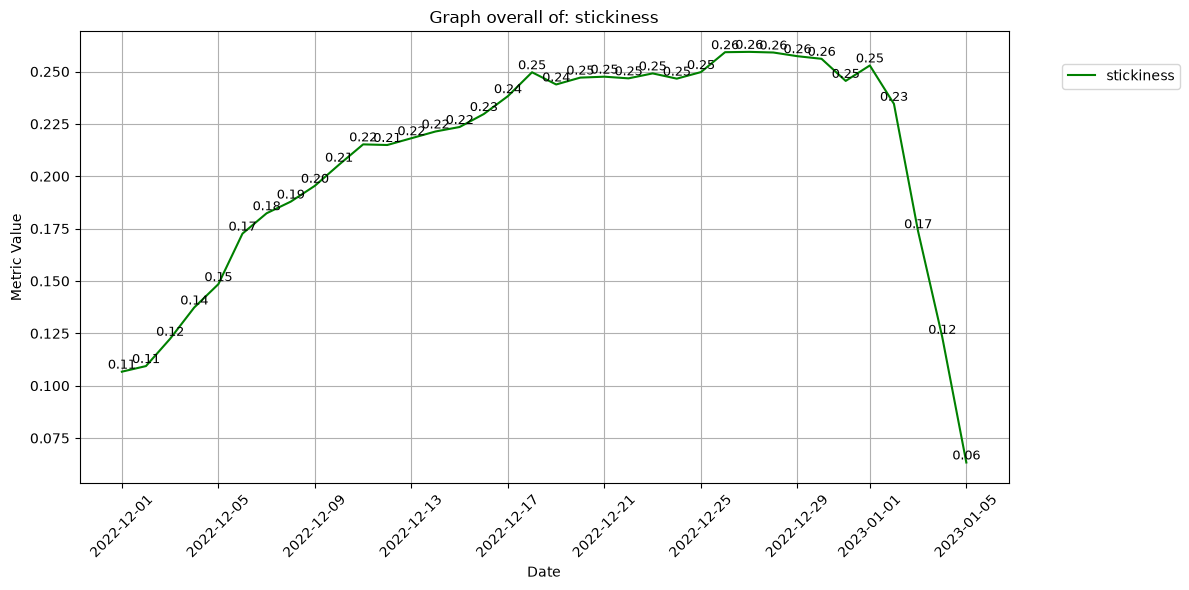

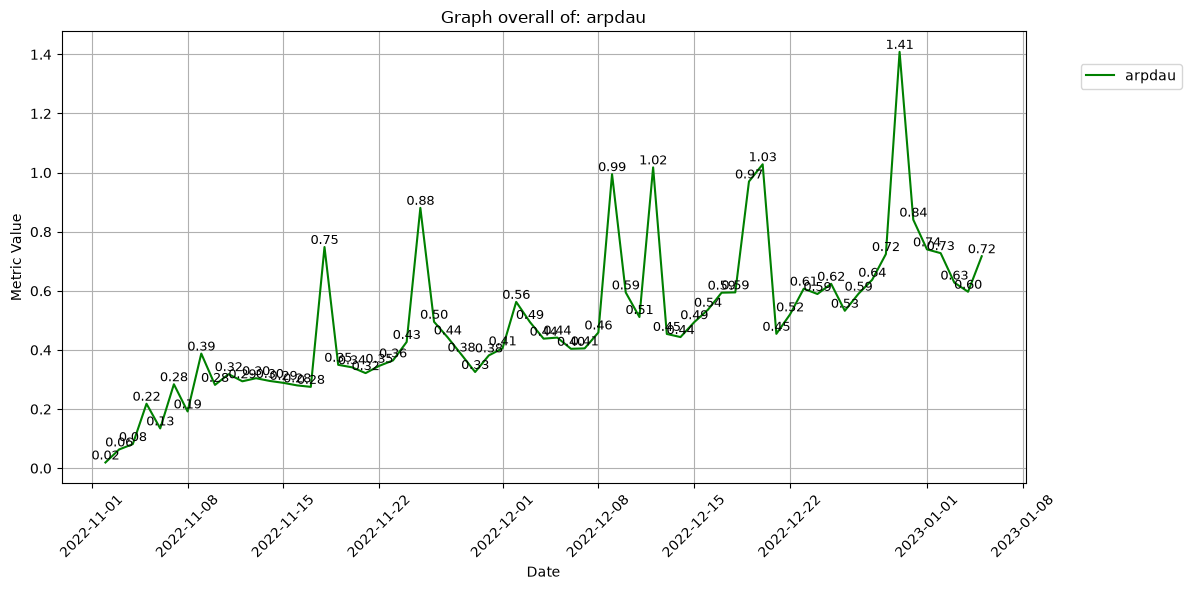

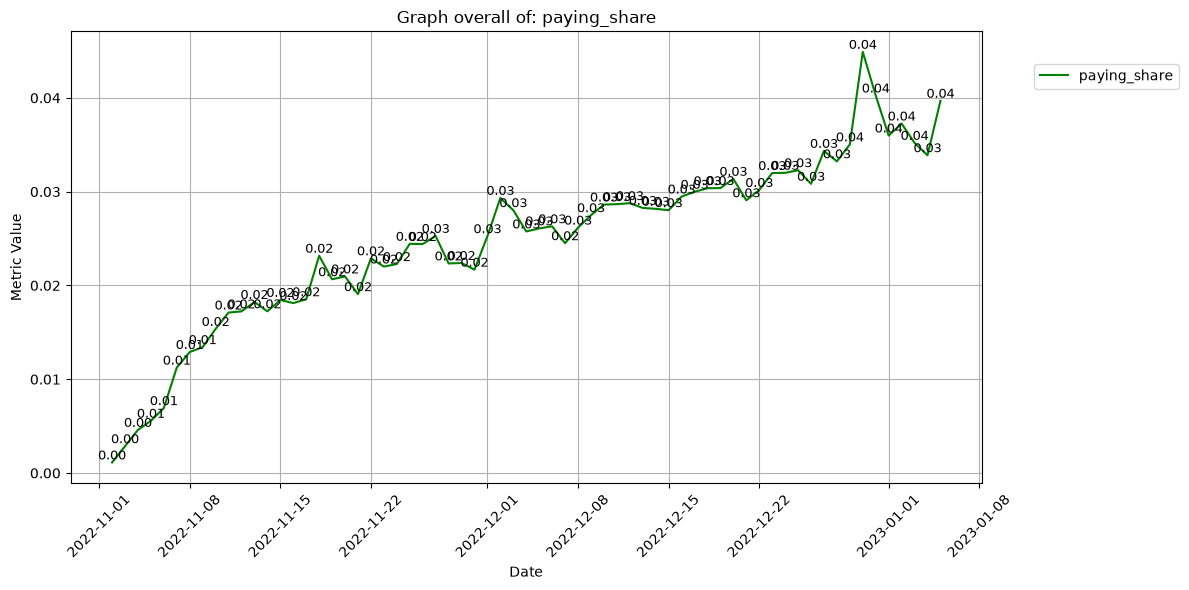

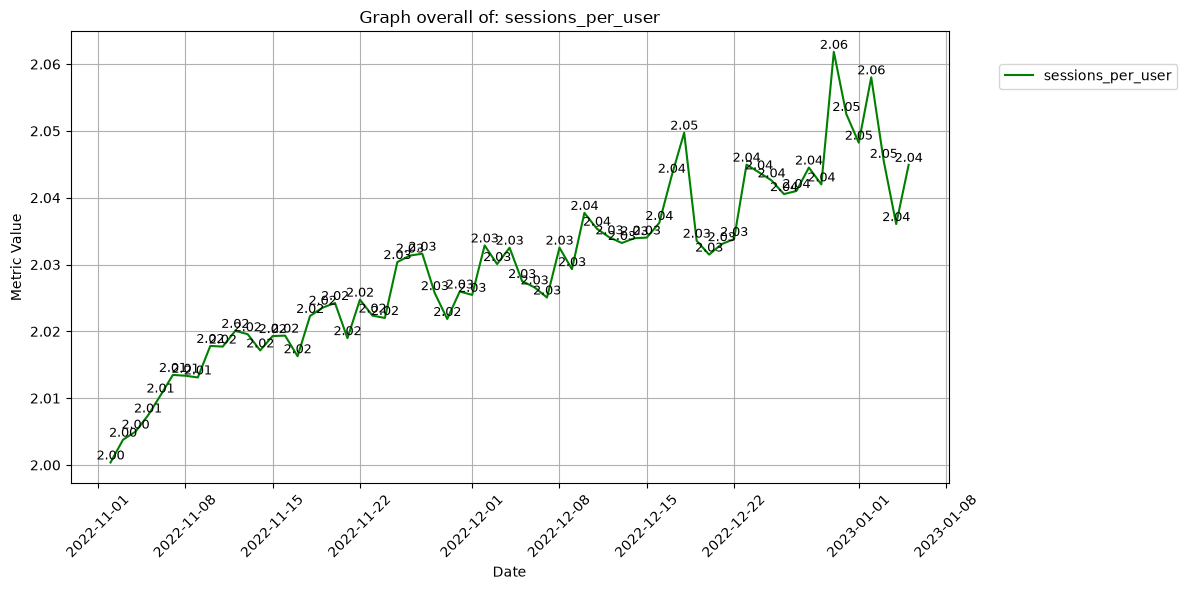

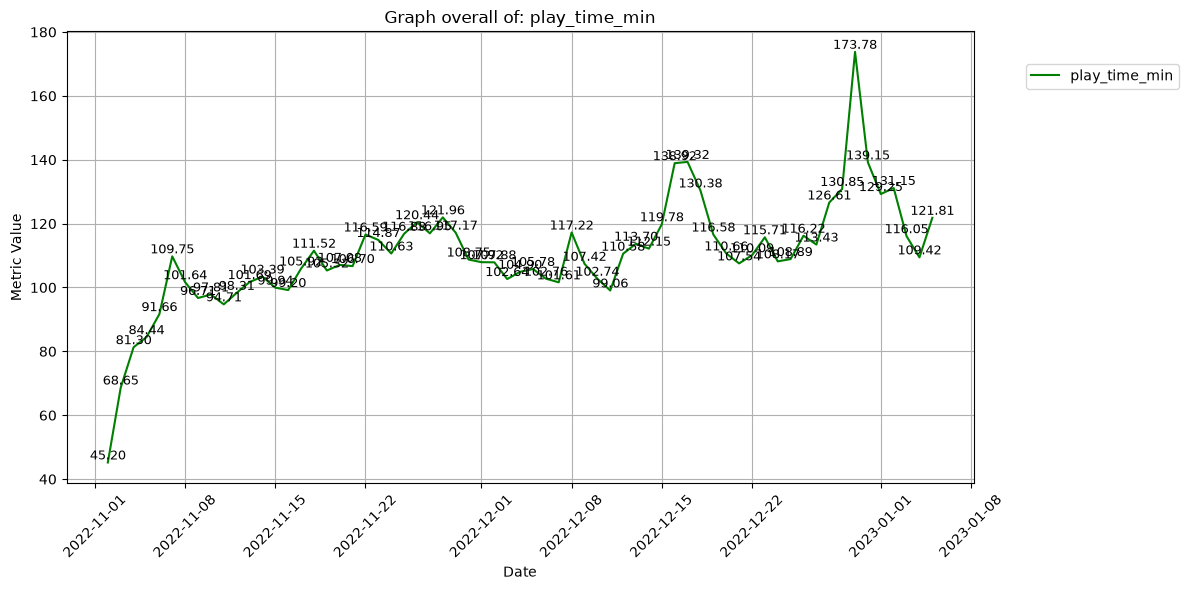

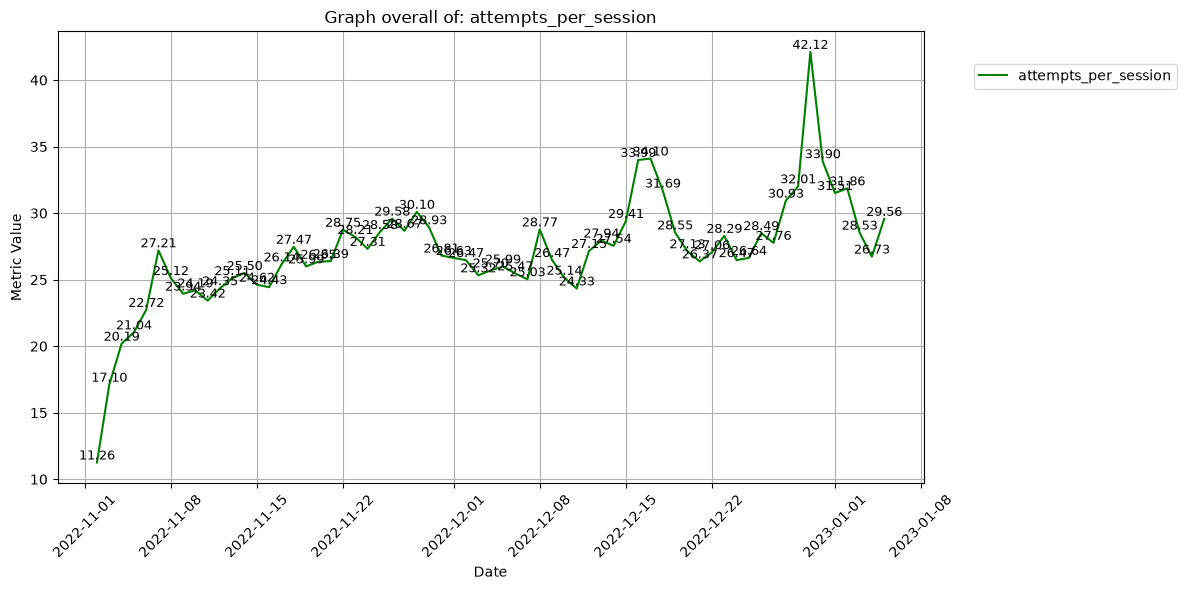

In [221]:
plots = ['stickiness', 'arpdau', 'paying_share', 'sessions_per_user', 'play_time_min', 'attempts_per_session']
for plot in plots:
    get_several_lines_plot(daily, 'date', [plot], title = f'Graph overall of: {plot}')

#### 2. Ride hailing  — 2 балла
У вас есть данные из приложения такси. Рассчитайте и визуализируйте:
- Ride Completion Rate — CR из заказа в завершенную поездку
- Acceptance Rate — доля заказов, принятых водителем (считаем, что приняты все заказы, кроме заказов со статусом 'No Driver Found')
- Cancellation Rate — доля отмененных заказов
- Rides per Driver — среднее число поездок на водителя
- Avg Ride Check — средний чек поездки
- Отношение RTA к ETA (что измеряет эта метрика?)

*Смотрим на подневную динамику

In [109]:
df_rh = pd.read_csv('hw_2_taxi.csv')

In [111]:
df_rh.head()

,date,time,order_uid,order_status,passenger_id,vehicle_type,pickup_location,drop_location,ETA,RTA,...,reason_for_cancelling_by_customer,cancelled_rides_by_driver,driver_cancellation_reason,incomplete_rides,incomplete_rides_reason,fare,ride_distance,driver_ratings,customer_rating,payment_method
0,2024-01-01,00:19:34,2a11faf27f77eae8,Completed,CID8362794,Bike,Udyog Vihar,Ambience Mall,9.0,10.8,...,NaN,NaN,NaN,NaN,NaN,99.0,37.98,4.8,4.8,Cash
1,2024-01-01,01:35:18,33ed1f6bad78bdc8,Completed,CID8300238,Go Mini,Basai Dhankot,Madipur,6.0,8.5,...,NaN,NaN,NaN,NaN,NaN,114.0,39.29,4.2,4.1,Uber Wallet
2,2024-01-01,01:37:50,e2fc1fc520e93b85,Cancelled by Driver,CID2030746,Go Sedan,Tughlakabad,Greater Kailash,6.0,7.4,...,NaN,1.0,More than permitted people in there,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-01,01:48:03,a130fd507acf7804,Cancelled by Driver,CID3231181,Auto,Palam Vihar,Kherki Daula Toll,5.0,NaN,...,NaN,1.0,Personal & Car related issues,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-01-01,01:49:56,cae2db8689a422fa,Cancelled by Driver,CID3381661,Go Sedan,Narsinghpur,Pulbangash,3.0,6.2,...,NaN,1.0,More than permitted people in there,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
df_rh.describe()

,ETA,RTA,cancelled_rides_by_customer,cancelled_rides_by_driver,incomplete_rides,fare,ride_distance,driver_ratings,customer_rating
count,139500.000000,125764.000000,10500.0,27000.0,9000.0,102000.000000,102000.000000,93000.000000,93000.000000
mean,6.564122,8.284368,1.0,1.0,1.0,508.295912,24.637012,4.230992,4.404584
std,3.154810,3.660055,0.0,0.0,0.0,395.805774,14.002138,0.436871,0.437819
min,1.000000,2.000000,1.0,1.0,1.0,50.000000,1.000000,3.000000,3.000000
25%,4.000000,5.200000,1.0,1.0,1.0,234.000000,12.460000,4.100000,4.200000
50%,6.000000,8.100000,1.0,1.0,1.0,414.000000,23.720000,4.300000,4.500000
75%,9.000000,11.200000,1.0,1.0,1.0,689.000000,36.820000,4.600000,4.800000
max,23.000000,20.000000,1.0,1.0,1.0,4277.000000,50.000000,5.000000,5.000000


In [115]:
df_rh['date'] = pd.to_datetime(df_rh['date'])

Описание данных (уникальный ключ order_uid)

- date — дата создания заказа
- time — время создания заказа
- order_uid — уникальный идентификатор заказа
- order_status — статус заказа
- passenger_id — уникальный идентификатор пассажира
- vehicle_type — тип транспорта 
- pickup_location — место отправления
- drop_location — место назначения
- ETA — прогнозное время прибытия водителя на место отправления (estimated time of arrival)
- RTA — реальное время прибытия водителя на место отправления (real time of arrival)
- driver_id — уникальный идентификатор водителя
- cancelled_rides_by_customer — флаг отмены поездки пассажиром
- reason_for_cancelling_by_customer — причина отмены поездки пассажиром
- cancelled_rides_by_driver — флаг отмены поездки водителем
- driver_cancellation_reason — причина отмены поездки водителем
- incomplete_rides — флаг незавершенной поездки
- incomplete_rides_reason — причина незавершенной поездки
- fare — цена поездки
- ride_distance – расстояние поездки
- driver_ratings — рейтинг водителя
- customer_rating — рейтинг пассажира
- payment_method – способ оплаты

In [118]:
daily = df_rh.groupby('date').agg(
    orders=('order_uid', 'count')
).reset_index()

In [121]:
daily['completed'] = df_rh[df_rh['order_status'] == 'Completed'].groupby('date')['order_uid'].count().reindex(daily['date']).fillna(0).values
daily['accepted'] = df_rh[df_rh['order_status'] != 'No Driver Found'].groupby('date')['order_uid'].count().reindex(daily['date']).fillna(0).values
daily['cancelled'] = df_rh[df_rh['order_status'].isin(['Cancelled by Customer', 'Cancelled by Driver'])].groupby('date')['order_uid'].count().reindex(daily['date']).fillna(0).values
daily['drivers'] = df_rh[df_rh['order_status'] == 'Completed'].groupby('date')['driver_id'].nunique().reindex(daily['date']).fillna(0).values
daily['avg_check'] = df_rh[df_rh['order_status'] == 'Completed'].groupby('date')['fare'].mean().reindex(daily['date']).values

rh_valid = df_rh[df_rh['RTA'].notna() & df_rh['ETA'].notna()]
daily['rta_eta_ratio'] = rh_valid.groupby('date').apply(
    lambda x: (x['RTA'] / x['ETA']).mean(), include_groups=False
).reindex(daily['date']).values


In [122]:
daily['completion_rate'] = daily['completed'] / daily['orders']
daily['acceptance_rate'] = daily['accepted'] / daily['orders']
daily['cancellation_rate'] = daily['cancelled'] / daily['orders']
daily['rides_per_driver'] = daily['completed'] / daily['drivers']

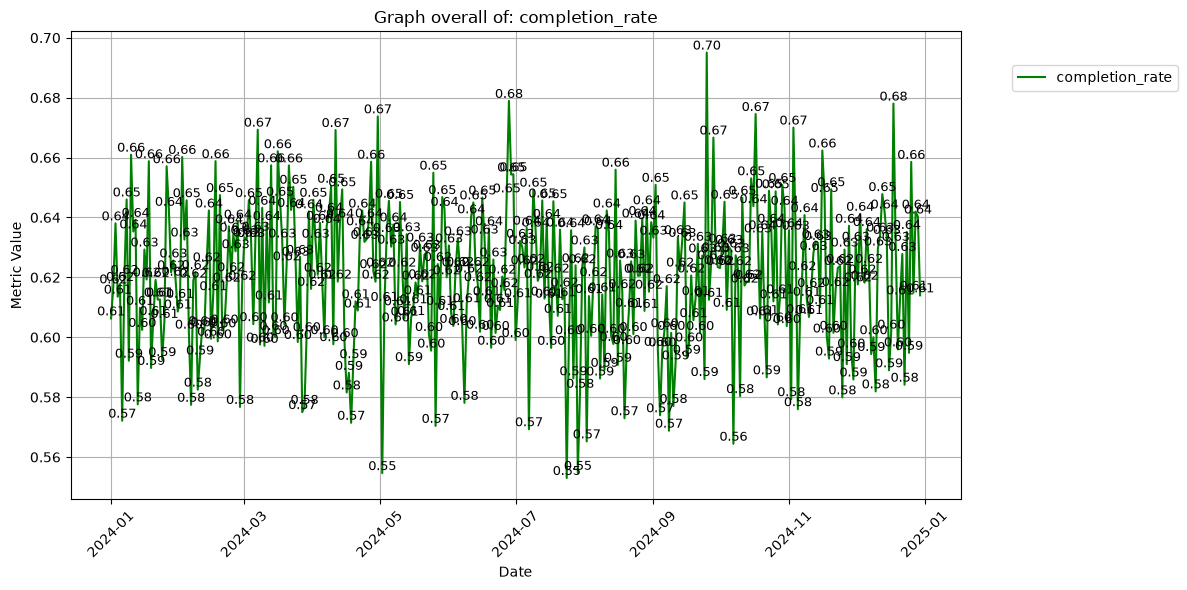

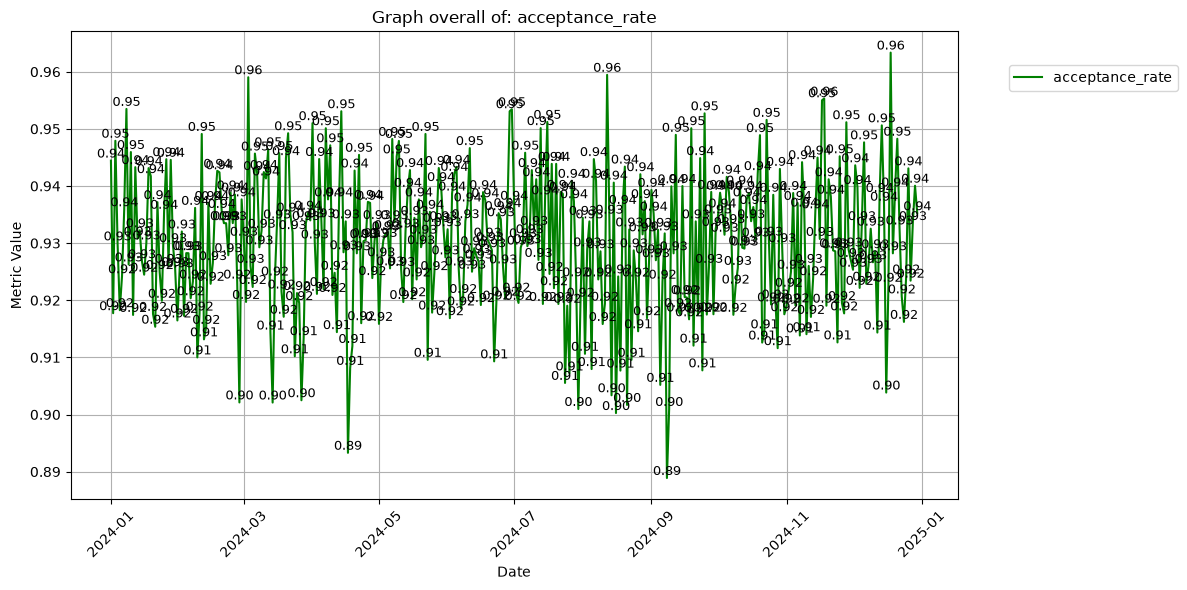

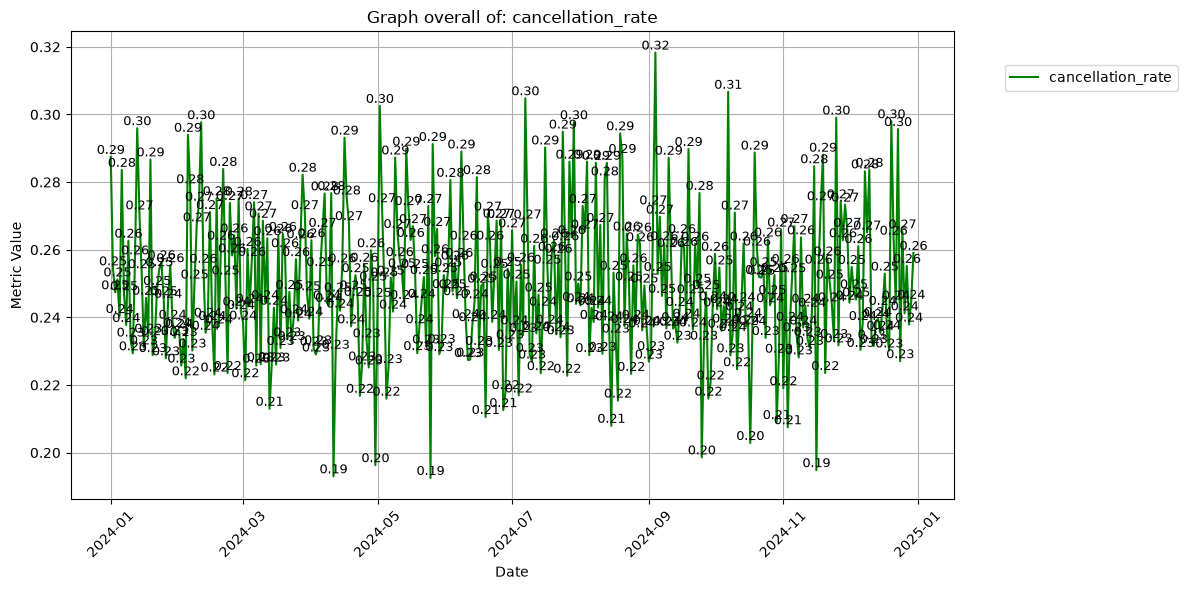

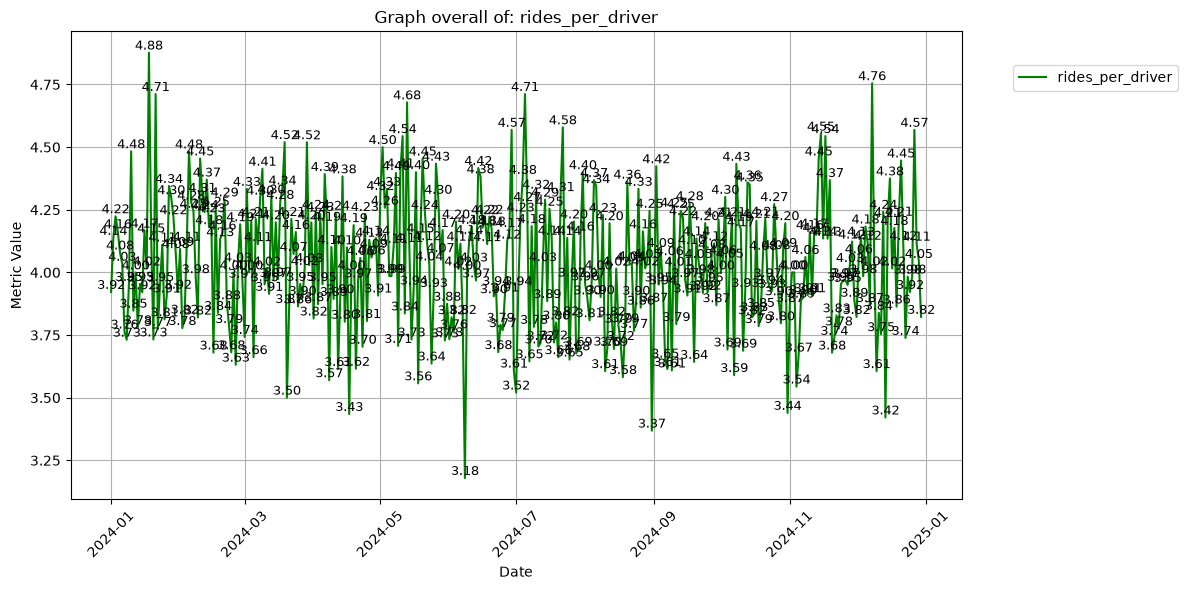

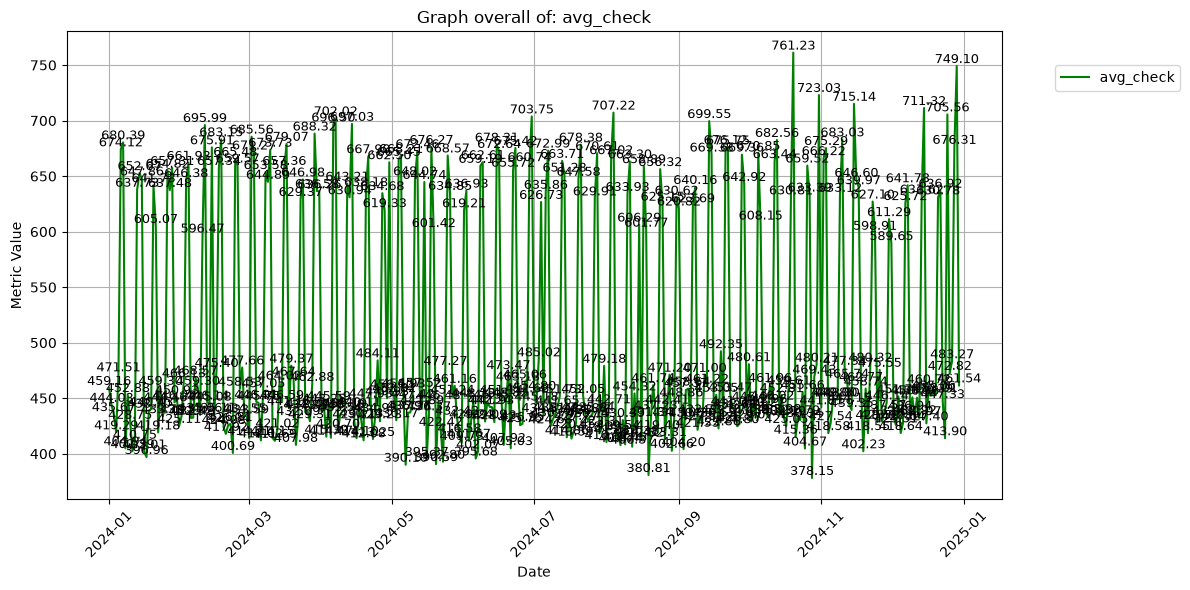

In [127]:
plots = ['completion_rate', 'acceptance_rate', 'cancellation_rate', 'rides_per_driver', 'avg_check']
for plot in plots:
    get_several_lines_plot(daily, 'date', [plot], title = f'Graph overall of: {plot}')

### Case Study. Запуск подкастов в стриминговом сервисе 🎧

**Легенда**  
Вы работаете продуктовым аналитиком в музыкальном стриминговом сервисе. Недавно в продукте запустился раздел с подкастами. Команда, отвечающая за запуск, хочет понять, стоит ли масштабировать и продвигать этот формат.

In [7]:
df_music_logs = pd.read_parquet('/Users/ramedlaw/Downloads/data-2/hw_2_streaming_logs.pqt')
df_music_subs = pd.read_parquet('/Users/ramedlaw/Downloads/data-2/hw_2_streaming_subs.pqt')

In [8]:
df_music_logs.head()

,datetime,uid,item_id,played_ratio_pct,track_length_seconds,content_type,is_first_date
0,2024-01-13 10:00:00,468300,7400764,100,225,music,0.0
1,2024-01-13 10:00:05,347600,3415205,100,250,music,0.0
2,2024-01-13 10:00:10,942900,6728180,1,270,music,0.0
3,2024-01-13 10:00:15,243500,5283544,100,195,music,0.0
4,2024-01-13 10:00:15,12700,8932363,100,245,music,0.0


In [9]:
df_music_subs.head()

,uid,start_date,end_date
0,600,2024-08-08,NaT
1,700,2024-03-29,NaT
2,800,2024-06-13,NaT
3,1100,2024-11-19,NaT
4,1400,2024-12-01,NaT


Описание данных hw_2_streaming_logs:

- datetime — дата-время взаимодействия с контентом
- uid — уникальный идентификатор пользователя
- item_id — уникальный идентификатор трека/эпизода
- played_ratio_pct — процент от длительности, который был воспроизведен
- track_length_seconds – длина трека/эпизода в секундах
- content_type — тип контента: музыка или подкаст
- is_first_date — флаг, является ли эта дата первой для пользователя в продукте

Описание данных hw_2_streaming_subs:

- uid — уникальный идентификатор пользователя
- start_date — дата начала подписки
- end_date — дата окончания подписки

In [10]:
df_music_logs.describe()

,datetime,uid,item_id,played_ratio_pct,track_length_seconds,is_first_date
count,46384540,4.638454e+07,4.638454e+07,4.638454e+07,4.638454e+07,4.638454e+07
mean,2024-06-28 17:34:56.984730880,4.985084e+05,4.714033e+06,6.478661e+01,2.056218e+02,4.652951e-03
min,2024-01-13 10:00:00,1.000000e+02,2.200000e+01,0.000000e+00,5.000000e+00,0.000000e+00
25%,2024-04-17 15:07:35,2.494000e+05,2.396712e+06,7.000000e+00,1.650000e+02,0.000000e+00
50%,2024-07-06 03:49:25,4.942000e+05,4.715228e+06,1.000000e+02,2.000000e+02,0.000000e+00
75%,2024-09-13 05:31:50,7.447000e+05,7.050562e+06,1.000000e+02,2.300000e+02,0.000000e+00
max,2024-11-09 08:13:20,1.000000e+06,9.390623e+06,1.590000e+02,2.495000e+03,1.000000e+00
std,NaN,2.873132e+05,2.701186e+06,4.408013e+01,7.544355e+01,6.805367e-02


In [11]:
df_music_subs.describe()

,uid,start_date,end_date
count,3603.000000,3603,247
mean,498535.720233,2024-07-19 06:28:04.596169984,2024-07-28 11:57:05.101214464
min,600.000000,2024-01-13 00:00:00,2024-02-22 00:00:00
25%,248400.000000,2024-04-26 12:00:00,2024-06-05 00:00:00
50%,493000.000000,2024-07-24 00:00:00,2024-08-04 00:00:00
75%,745750.000000,2024-10-13 00:00:00,2024-09-18 00:00:00
max,999800.000000,2024-12-31 00:00:00,2024-11-09 00:00:00
std,287526.800206,NaN,NaN


#### 3. Метрики роста  — 2 балла

Рассчитайте и визуализируйте:
- DAU, MAU, WAU;
- Количество новых премиум-подписчиков (за неделю и месяц);
- Проникновение подкастов — долю юзеров, послушавших подкаст хотя бы раз (за неделю и месяц).

Сделайте выводы:
- Есть ли выраженный тренд?
- Нет ли подозрений, что с раскаткой раздела что-то могло пойти не так (изменение тренда, выраженные ступеньки)?
- Как выглядит адопшен? Можно ли предположить наличие каких-то эффектов в пользовательском взаимодействии с новым разделом?

In [27]:
df_music_logs['datetime'] = pd.to_datetime(df_music_logs['datetime'])
df_music_logs['date'] = df_music_logs['datetime'].dt.normalize()
df_music_subs['start_date'] = pd.to_datetime(df_music_subs['start_date'])
df_music_subs['end_date'] = pd.to_datetime(df_music_subs['end_date'])


In [37]:
df_music_logs['played_sec'] = df_music_logs['played_ratio_pct'] / 100 * df_music_logs['track_length_seconds']
df_music_logs['played_sec']

0           225.00
1           250.00
2             2.70
3           195.00
4           245.00
             ...  
46384535      3.45
46384536      0.00
46384537     12.30
46384538     15.60
46384539     13.20
Name: played_sec, Length: 46384540, dtype: float64

In [38]:
df_music_logs['content_type'].value_counts()

content_type
music      46325679
podcast       58861
Name: count, dtype: int64

In [41]:
df_music_logs['podcast_interaction'] = ((df_music_logs['content_type'] == 'podcast') & ((df_music_logs['played_ratio_pct'] >= 30) | (df_music_logs['played_sec'] > 120)))
df_music_logs[df_music_logs['podcast_interaction']== True]

,datetime,uid,item_id,played_ratio_pct,track_length_seconds,content_type,is_first_date,date,played_sec,podcast_interaction
32526667,2024-09-01 00:04:05,852400,801028,100,880,podcast,0.0,2024-09-01,880.0,True
32527513,2024-09-01 00:08:10,261000,965957,92,860,podcast,0.0,2024-09-01,791.2,True
32527517,2024-09-01 00:08:10,261000,965957,92,860,podcast,0.0,2024-09-01,791.2,True
32528143,2024-09-01 00:11:00,11700,5465707,100,1180,podcast,0.0,2024-09-01,1180.0,True
32528225,2024-09-01 00:11:20,229300,356101,100,1185,podcast,0.0,2024-09-01,1185.0,True
...,...,...,...,...,...,...,...,...,...,...
46382334,2024-11-09 07:44:25,291500,4579223,100,1775,podcast,0.0,2024-11-09,1775.0,True
46382796,2024-11-09 07:49:40,147800,8236589,100,1345,podcast,0.0,2024-11-09,1345.0,True
46382887,2024-11-09 07:51:05,396800,4905306,26,965,podcast,0.0,2024-11-09,250.9,True
46382932,2024-11-09 07:51:40,866000,605020,100,600,podcast,0.0,2024-11-09,600.0,True


In [67]:
df_music_logs['is_podcast'] = df_music_logs['content_type'] == 'podcast'
df_music_logs['week'] = df_music_logs['date'].dt.to_period('W').dt.start_time
df_music_logs['month'] = df_music_logs['date'].dt.to_period('M').dt.start_time

In [68]:
df_music_logs['date'].min(), df_music_logs['date'].max()

(Timestamp('2024-01-13 00:00:00'), Timestamp('2024-11-09 00:00:00'))

In [107]:
first_week = df_music_logs['week'].min() + timedelta(days=7)
last_week = df_music_logs['week'].max() - timedelta(days=7)
first_month = df_music_logs['month'].min() + pd.DateOffset(months=1)
last_month = df_music_logs['month'].max() - pd.DateOffset(months=1)
first_week, last_week, first_month, last_month

(Timestamp('2024-01-15 00:00:00'),
 Timestamp('2024-10-28 00:00:00'),
 Timestamp('2024-02-01 00:00:00'),
 Timestamp('2024-10-01 00:00:00'))

In [108]:
launch_date = df_music_logs[df_music_logs['is_podcast']]['date'].min()
launch_date

Timestamp('2024-09-01 00:00:00')

In [142]:
user_day = df_music_logs.groupby(['date', 'uid']).agg(
    podcast_any=('is_podcast', 'max'),
    podcast_interaction=('podcast_interaction', 'max')
).reset_index()
user_day['week'] = user_day['date'].dt.to_period('W').dt.start_time
user_day['month'] = user_day['date'].dt.to_period('M').dt.start_time
user_day.head()

,date,uid,podcast_any,podcast_interaction,week,month
0,2024-01-13,100,False,False,2024-01-08,2024-01-01
1,2024-01-13,800,False,False,2024-01-08,2024-01-01
2,2024-01-13,1300,False,False,2024-01-08,2024-01-01
3,2024-01-13,1400,False,False,2024-01-08,2024-01-01
4,2024-01-13,1600,False,False,2024-01-08,2024-01-01


##### DAU, WAU, MAU

In [190]:
daily_music = user_day.groupby('date')['uid'].nunique().reset_index(name='dau')
daily_music.head()

,date,dau
0,2024-01-13,1985
1,2024-01-14,2547
2,2024-01-15,2342
3,2024-01-16,2471
4,2024-01-17,2549


In [191]:
first_date = daily_music['date'].min()
mau, wau = {}, {}
for d in daily_music['date']:
    if d - timedelta(days=29) >= first_date:
        mask = (user_day['date'] >= d - timedelta(days=29)) & (user_day['date'] <= d)
        mau[d] = user_day.loc[mask, 'uid'].nunique()
    if d - timedelta(days=6) >= first_date:
        mask = (user_day['date'] >= d - timedelta(days=6)) & (user_day['date'] <= d)
        wau[d] = user_day.loc[mask, 'uid'].nunique()
daily_music['mau'] = daily_music['date'].map(mau)
daily_music['wau'] = daily_music['date'].map(wau)

In [188]:
daily_music = daily_music[daily_music['date'] < daily_music['date'].max()]
daily_music

,date,dau,mau,wau
0,2024-01-13,1985,NaN,NaN
1,2024-01-14,2547,NaN,NaN
2,2024-01-15,2342,NaN,NaN
3,2024-01-16,2471,NaN,NaN
4,2024-01-17,2549,NaN,NaN
...,...,...,...,...
260,2024-09-29,4536,8033.0,6954.0
261,2024-09-30,4128,8050.0,6980.0
262,2024-10-01,4398,8066.0,7002.0
263,2024-10-02,4465,8089.0,7028.0


In [195]:
daily_music.dropna()

,date,dau,mau,wau
29,2024-02-11,2760,5175.0,4368.0
30,2024-02-12,2560,5192.0,4382.0
31,2024-02-13,2673,5201.0,4394.0
32,2024-02-14,2729,5200.0,4404.0
33,2024-02-15,2729,5211.0,4424.0
...,...,...,...,...
297,2024-11-05,4777,9069.0,8058.0
298,2024-11-06,4818,9112.0,8086.0
299,2024-11-07,4935,9149.0,8078.0
300,2024-11-08,4913,9192.0,8061.0


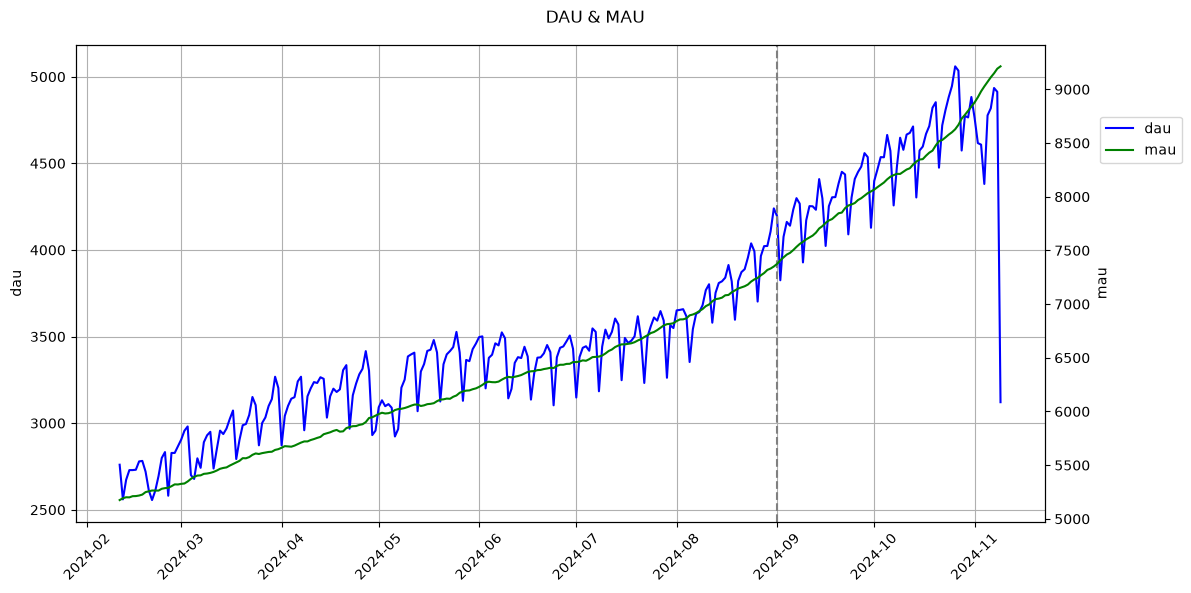

In [193]:
get_line_plot(daily_music.dropna(), 'date', ['dau', 'mau'], title='DAU & MAU', vline=launch_date)

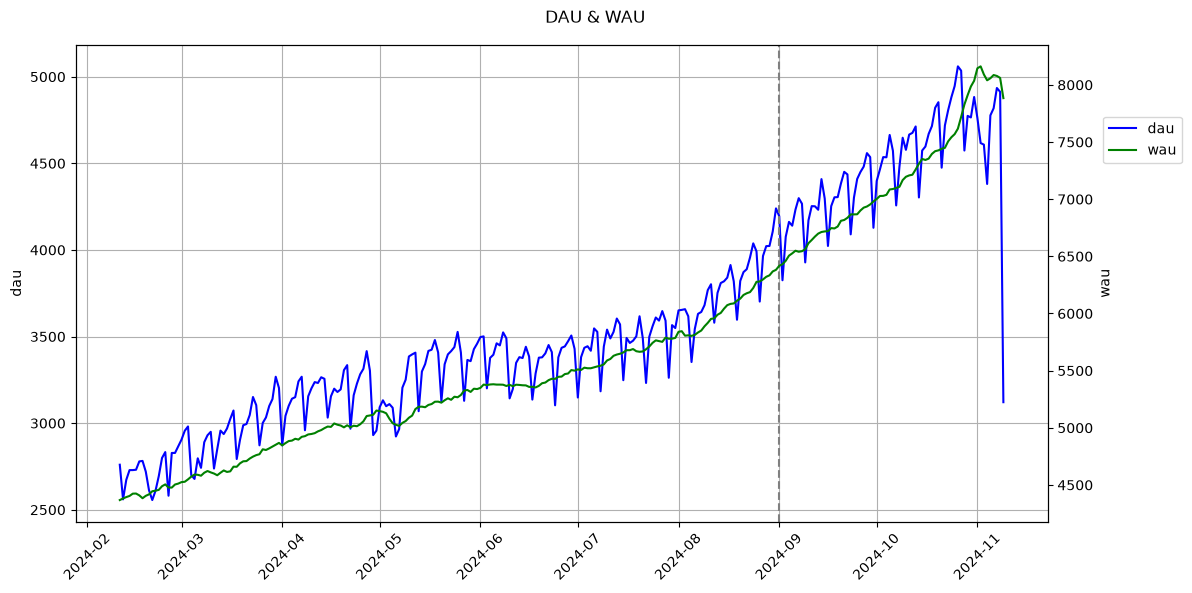

In [194]:
get_line_plot(daily_music.dropna(), 'date', ['dau', 'wau'], title='DAU & WAU', vline=launch_date)

##### Новые премиум-подписчики

In [196]:
df_music_subs['week'] = df_music_subs['start_date'].dt.to_period('W').dt.start_time
df_music_subs['month'] = df_music_subs['start_date'].dt.to_period('M').dt.start_time

In [216]:
new_subs_week = df_music_subs.groupby('week')['uid'].nunique().reset_index(name='new_subs')
new_subs_week = new_subs_week[(new_subs_week['week'] >= first_week) & (new_subs_week['week'] <= last_week)]
new_subs_week = new_subs_week.rename(columns={'week': 'date'})
new_subs_week

,date,new_subs
1,2024-01-15,49
2,2024-01-22,63
3,2024-01-29,42
4,2024-02-05,57
5,2024-02-12,54
6,2024-02-19,67
7,2024-02-26,65
8,2024-03-04,62
9,2024-03-11,59
10,2024-03-18,65


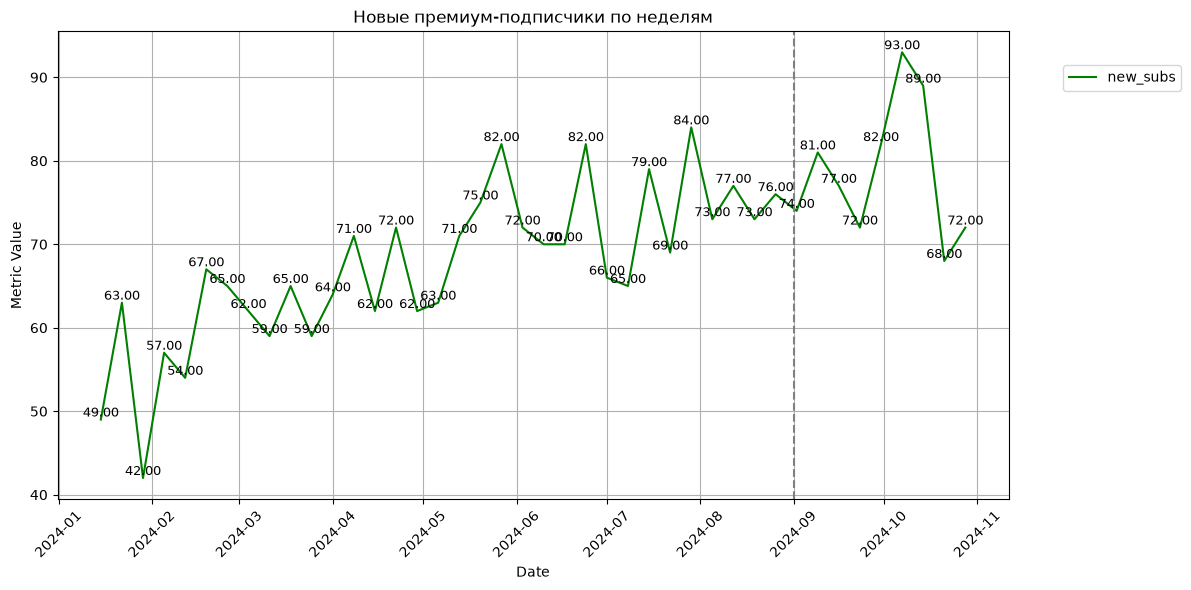

In [217]:
get_several_lines_plot(new_subs_week, 'date', ['new_subs'], title='Новые премиум-подписчики по неделям', vline=launch_date)

In [229]:
new_subs_month = df_music_subs.groupby('month')['uid'].nunique().reset_index(name='new_subs')
new_subs_month = new_subs_month[(new_subs_month['month'] >= first_month) & (new_subs_month['month'] <= last_month)]
new_subs_month = new_subs_month.rename(columns={'month': 'date'})
new_subs_month

,date,new_subs
1,2024-02-01,232
2,2024-03-01,272
3,2024-04-01,290
4,2024-05-01,300
5,2024-06-01,326
6,2024-07-01,311
7,2024-08-01,344
8,2024-09-01,322
9,2024-10-01,355


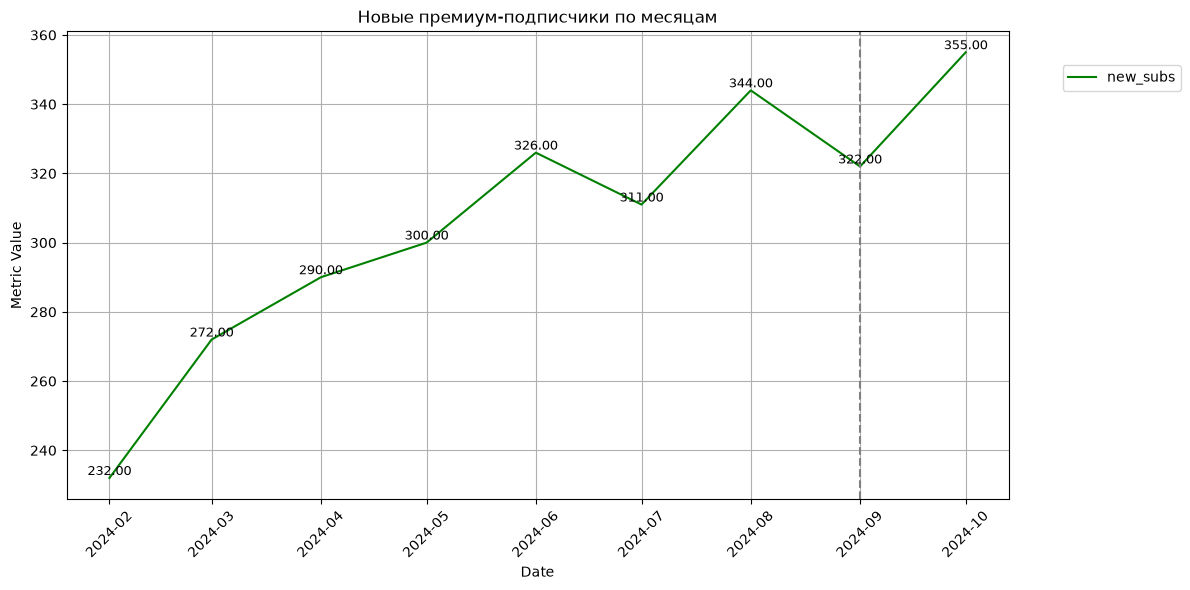

In [230]:
get_several_lines_plot(new_subs_month, 'date', ['new_subs'], title='Новые премиум-подписчики по месяцам', vline=launch_date)

##### Проникновение подкастов

In [238]:
user_week = user_day.groupby(['week', 'uid'])[['podcast_any', 'podcast_interaction']].max().reset_index()
user_week.head()

,week,uid,podcast_any,podcast_interaction
0,2024-01-08,100,False,False
1,2024-01-08,300,False,False
2,2024-01-08,700,False,False
3,2024-01-08,800,False,False
4,2024-01-08,1300,False,False


In [248]:
penetration_week = user_week.groupby('week')[['podcast_any', 'podcast_interaction']].mean().reset_index()
penetration_week = penetration_week[(penetration_week['week'] >= first_week) & (penetration_week['week'] <= last_week)]
penetration_week = penetration_week.rename(columns={'week': 'date'})
penetration_week.tail(12)

,date,podcast_any,podcast_interaction
31,2024-08-12,0.000000,0.000000
32,2024-08-19,0.000000,0.000000
33,2024-08-26,0.028518,0.016207
34,2024-09-02,0.122536,0.073033
35,2024-09-09,0.123400,0.073831
36,2024-09-16,0.142021,0.086003
37,2024-09-23,0.136037,0.085994
38,2024-09-30,0.125406,0.078290
39,2024-10-07,0.124380,0.080854
40,2024-10-14,0.133163,0.084287


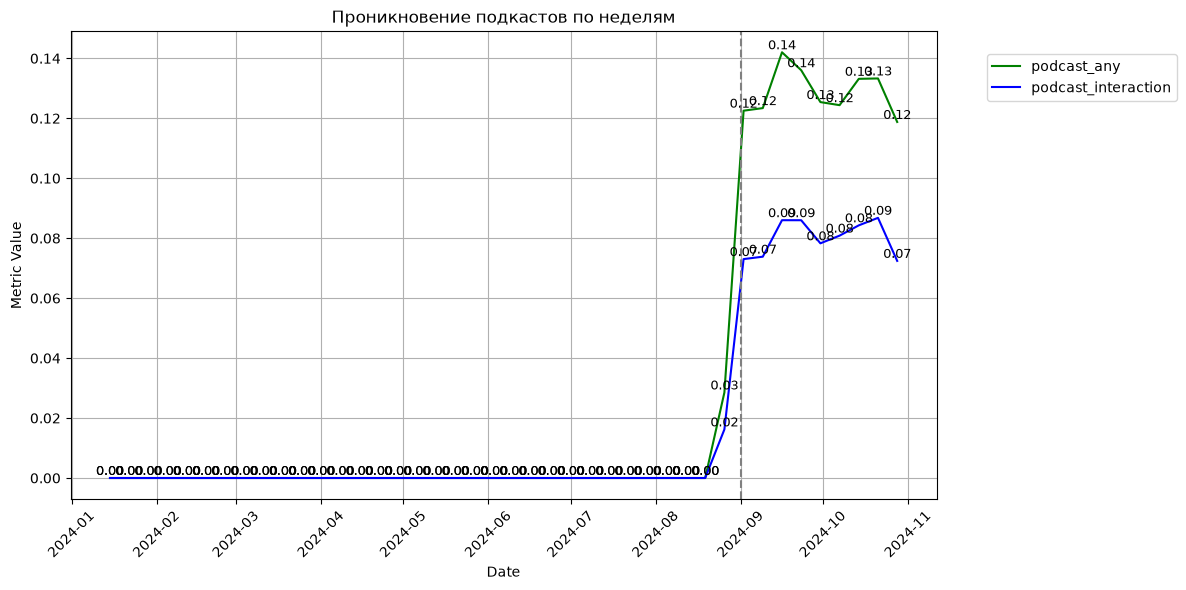

In [252]:
get_several_lines_plot(penetration_week, 'date', ['podcast_any', 'podcast_interaction'], title='Проникновение подкастов по неделям', vline=launch_date)

In [254]:
user_month = user_day.groupby(['month', 'uid'])[['podcast_any', 'podcast_interaction']].max().reset_index()
penetration_month = user_month.groupby('month')[['podcast_any', 'podcast_interaction']].mean().reset_index()
penetration_month = penetration_month[(penetration_month['month'] >= first_month) & (penetration_month['month'] <= last_month)]
penetration_month = penetration_month.rename(columns={'month': 'date'})
penetration_month

,date,podcast_any,podcast_interaction
1,2024-02-01,0.000000,0.000000
2,2024-03-01,0.000000,0.000000
3,2024-04-01,0.000000,0.000000
4,2024-05-01,0.000000,0.000000
5,2024-06-01,0.000000,0.000000
6,2024-07-01,0.000000,0.000000
7,2024-08-01,0.000000,0.000000
8,2024-09-01,0.286335,0.172671
9,2024-10-01,0.277979,0.174655


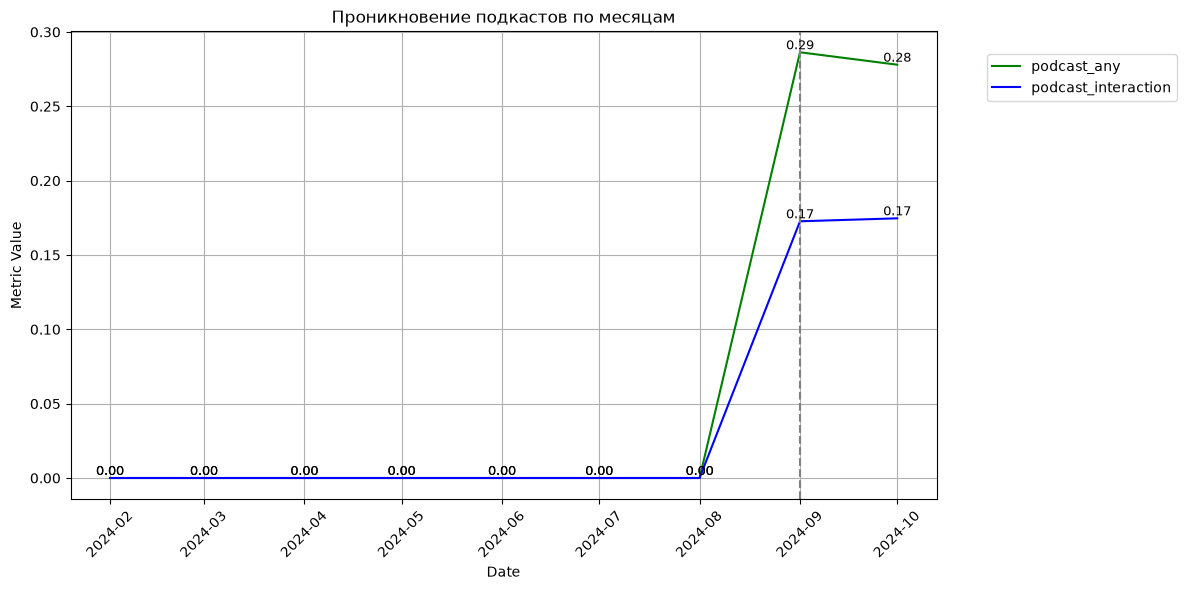

In [257]:
get_several_lines_plot(penetration_month, 'date', ['podcast_any', 'podcast_interaction'], title='Проникновение подкастов по месяцам', vline=launch_date)

##### Выводы по заданию 3

- Тренд: Рост выраженный: DAU с 2000 до 5000, MAU с 5200 до 9200, есть недельная сезонность. Новые подписчики растут, потом выходят на плато (около 80 в неделю, 350 в месяц). Рост начался и виден с самого старта 2024-го годад, задолго до появления подкастов.
- Раскатка раздела: Ступенек в момент запуска нет, тренд почти не изменился. Падения в конце графиков (последний день DAU, последняя неделя подписчиков, ноябрь в проникновении) это неполные периоды, а не реальные события.
- Адопшен: Проникновение подкастов резко выросло с 0 до 12% в неделю в конце августа, потом колебалось и вернулось до 12%. Месячное около 29%, заметно выше недельного. Многие попробовали, но регулярно слушает меньшая часть. 
Похоже на эффект новизны. Подкастов в логах очень мало (58 тысяч событий против 46 миллионов у музыки). Месячное проникновение почти не изменилось. «Включил» 28-29%, а "послушал" вообще 17%

#### 4. Метрики продукта (шаг 1)  — 2 балла

Рассчитайте и визуализируйте как для всех пользователей в совокупности, так и для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами (грубо говоря разделяем юзеров на тех, кто слушает только музыку и тех, кто слушает еще и подкасты):
1. Среднее время прослушивания на пользователя.
2. Среднее число треков/эпизодов на пользователя (среднее число item_id). Посчитайте метрику, как от уникальных, так и от не уникальных item_id. Подумайте, что показывает каждая из них?
3. Долю премиум-подписчиков. Обратите внимание, что нам нужна активная подписка, если пользователь отписался в том же периоде, что подписался, мы больше не считаем подписку активной.

Рассчитайте и визуализируйте как по всем item_id, так и в разрезе типов контента:
- Долю дослушанных треков/эпизодов до конца. Обратите внимание, данная метрика уже не пользовательская.

Периоды — неделя и месяц. Неполные периоды нужно обрезать, если они мешают чтению графиков.   
Признак взаимодействия присвайвайте только для периода, когда оно действительно было.   
Для месячной динамики метрик по признаку взаимодействия с подкастами у вас получится всего 2 точки, такая визуализая тоже полезна, она сглаживает недельные колебания и помогает оценивать тренд в масштабе года.

Сделайте выводы:
- Есть ли выраженный тренд?
- Изменилась ли метрика после запуска подкастов?
- Отличается ли метрика сегмента, взаимодействовавшего с подкастами, от тех, кто слушал только музыку? (будьте аккуратны с выводами в этом пункте, мы не проверяем изменение на каузальность, поэтому не можем быть уверены где причина, а где следствие)
- Есть ли отличия между типами контента?

*За взаимодействие с подкастами давайте считать только прослушивание >= 30% или более 2х минут контента*

##### Пользовательские метрики по неделям

In [321]:
user_week_stats = df_music_logs.groupby(['week', 'uid']).agg(
    time_min=('played_sec', 'sum'),
    items=('item_id', 'count'),
    unique_items=('item_id', 'nunique'),
    podcast=('podcast_interaction', 'max')
).reset_index()
user_week_stats['time_min'] = user_week_stats['time_min'] / 60

In [322]:
user_week_stats['segment'] = 'music'
user_week_stats.loc[user_week_stats['podcast'], 'segment'] = 'podcast'
user_week_stats['segment'].value_counts()

segment
music      239782
podcast      5831
Name: count, dtype: int64

In [323]:
user_week_stats = user_week_stats.merge(df_music_subs[['uid', 'start_date', 'end_date']], on='uid', how='left')
week_end = user_week_stats['week'] + timedelta(days=6)
user_week_stats['premium'] = (user_week_stats['start_date'] <= week_end) & (user_week_stats['end_date'].isna() | (user_week_stats['end_date'] > week_end))

In [324]:
user_week_stats = user_week_stats[(user_week_stats['week'] >= first_week) & (user_week_stats['week'] <= last_week)]
user_week_stats.head()

,week,uid,time_min,items,unique_items,podcast,segment,start_date,end_date,premium
2973,2024-01-15,100,53.575833,21,21,False,music,NaT,NaT,False
2974,2024-01-15,700,413.457500,150,150,False,music,2024-03-29,NaT,False
2975,2024-01-15,800,855.160833,443,419,False,music,2024-06-13,NaT,False
2976,2024-01-15,900,127.795000,234,191,False,music,NaT,NaT,False
2977,2024-01-15,1300,0.250000,1,1,False,music,NaT,NaT,False


In [325]:
metrics = ['time_min', 'items', 'unique_items', 'premium']

week_all = user_week_stats.groupby('week')[metrics].mean().reset_index()
week_all['segment'] = 'all'
week_seg = user_week_stats.groupby(['week', 'segment'])[metrics].mean().reset_index()

week_metrics = pd.concat([week_all, week_seg])
week_metrics.tail(12)

,week,time_min,items,unique_items,premium,segment
40,2024-09-23,399.172392,189.402454,131.957678,0.315607,music
41,2024-09-23,665.387281,248.209030,179.443144,0.382943,podcast
42,2024-09-30,407.201344,192.604530,133.604683,0.321855,music
43,2024-09-30,680.617910,261.798198,185.209009,0.369369,podcast
44,2024-10-07,403.497434,191.876517,134.157800,0.323393,music
45,2024-10-07,652.514543,251.712095,180.357751,0.376491,podcast
46,2024-10-14,400.247384,187.495515,131.696074,0.325981,music
47,2024-10-14,632.756084,254.404153,180.052716,0.402556,podcast
48,2024-10-21,398.937276,187.542695,131.390355,0.323262,music
49,2024-10-21,665.702407,273.582090,196.234328,0.397015,podcast


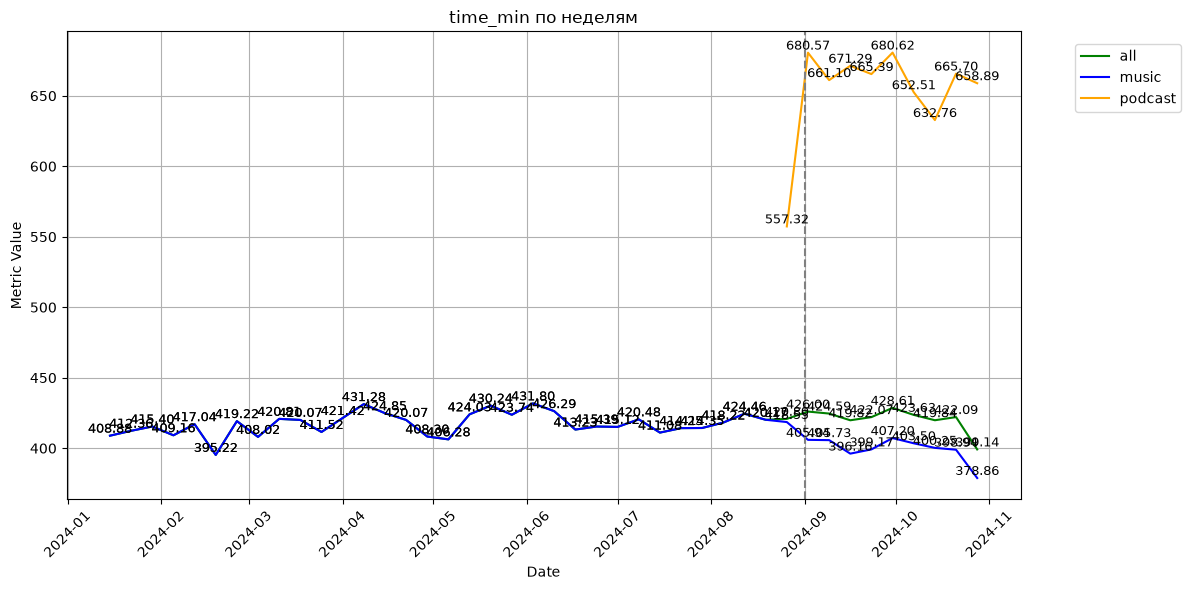

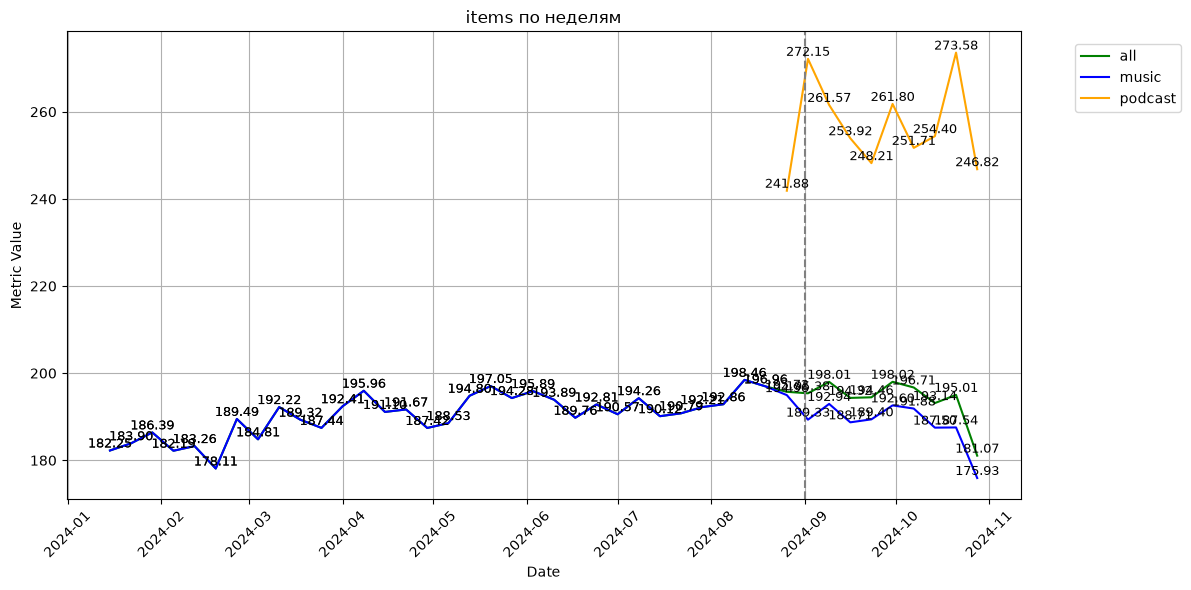

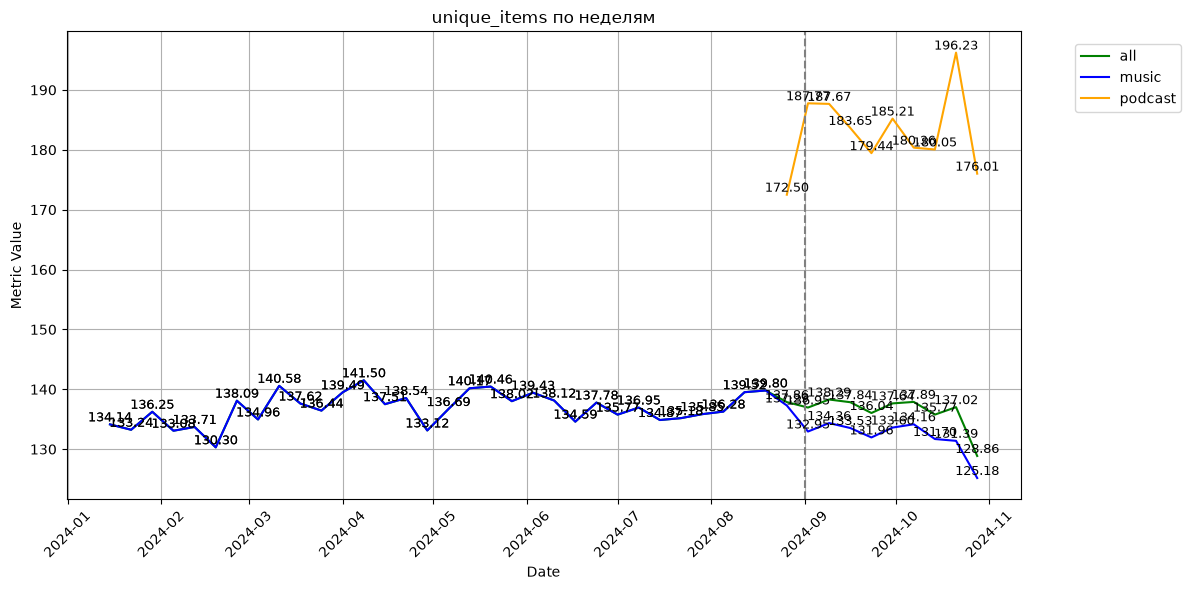

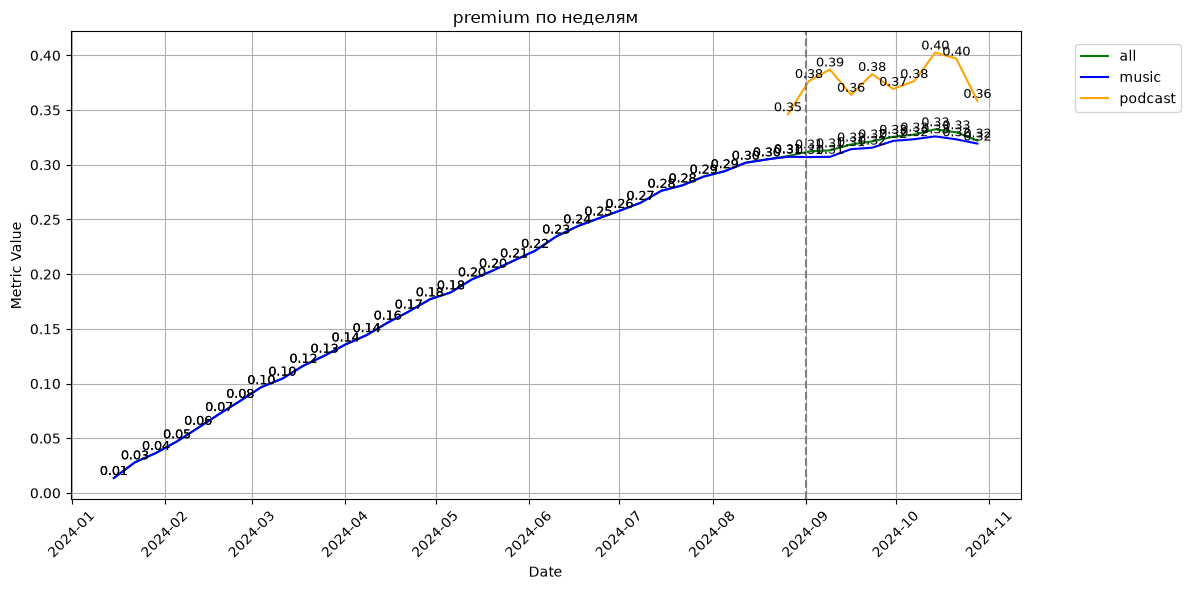

In [326]:
for metric in metrics:
    plot_df = week_metrics.pivot(index='week', columns='segment', values=metric).reset_index()
    plot_df = plot_df.rename(columns={'week': 'date'})
    get_several_lines_plot(plot_df, 'date', ['all', 'music', 'podcast'], title=f'{metric} по неделям', vline=launch_date)

##### Пользовательские метрики по месяцам

In [366]:
user_month_stats = df_music_logs.groupby(['month', 'uid']).agg(
    time_min=('played_sec', 'sum'),
    items=('item_id', 'count'),
    unique_items=('item_id', 'nunique'),
    podcast=('podcast_interaction', 'max')
).reset_index()
user_month_stats['time_min'] = user_month_stats['time_min'] / 60

In [367]:
user_month_stats['segment'] = 'music'
user_month_stats.loc[user_month_stats['podcast'], 'segment'] = 'podcast'
user_month_stats['segment'].value_counts()

segment
music      70243
podcast     3651
Name: count, dtype: int64

In [368]:
user_month_stats = user_month_stats.merge(df_music_subs[['uid', 'start_date', 'end_date']], on='uid', how='left')
month_end = user_month_stats['month'] + pd.offsets.MonthEnd(0)
user_month_stats['premium'] = (user_month_stats['start_date'] <= month_end) & (
    user_month_stats['end_date'].isna() | (user_month_stats['end_date'] > month_end))

In [369]:
user_month_stats = user_month_stats[(user_month_stats['month'] >= first_month) & (user_month_stats['month'] <= last_month)]

In [370]:
month_all = user_month_stats.groupby('month')[metrics].mean().reset_index()
month_all['segment'] = 'all'
month_seg = user_month_stats.groupby(['month', 'segment'])[metrics].mean().reset_index()

month_metrics = pd.concat([month_all, month_seg])
month_metrics

,month,time_min,items,unique_items,premium,segment
0,2024-02-01,1418.398049,632.118324,344.792980,0.070768,all
1,2024-03-01,1534.470850,697.535298,373.309919,0.111366,all
2,2024-04-01,1518.356046,691.260695,361.788794,0.149975,all
3,2024-05-01,1556.143511,714.012989,365.561257,0.186658,all
4,2024-06-01,1518.431987,695.950000,359.373220,0.224149,all
5,2024-07-01,1518.798314,700.374781,358.648597,0.252630,all
6,2024-08-01,1549.270961,721.286605,363.654284,0.277522,all
7,2024-09-01,1519.779167,703.548323,363.524720,0.288447,all
8,2024-10-01,1576.550408,725.815058,376.625141,0.299005,all
0,2024-02-01,1418.398049,632.118324,344.792980,0.070768,music


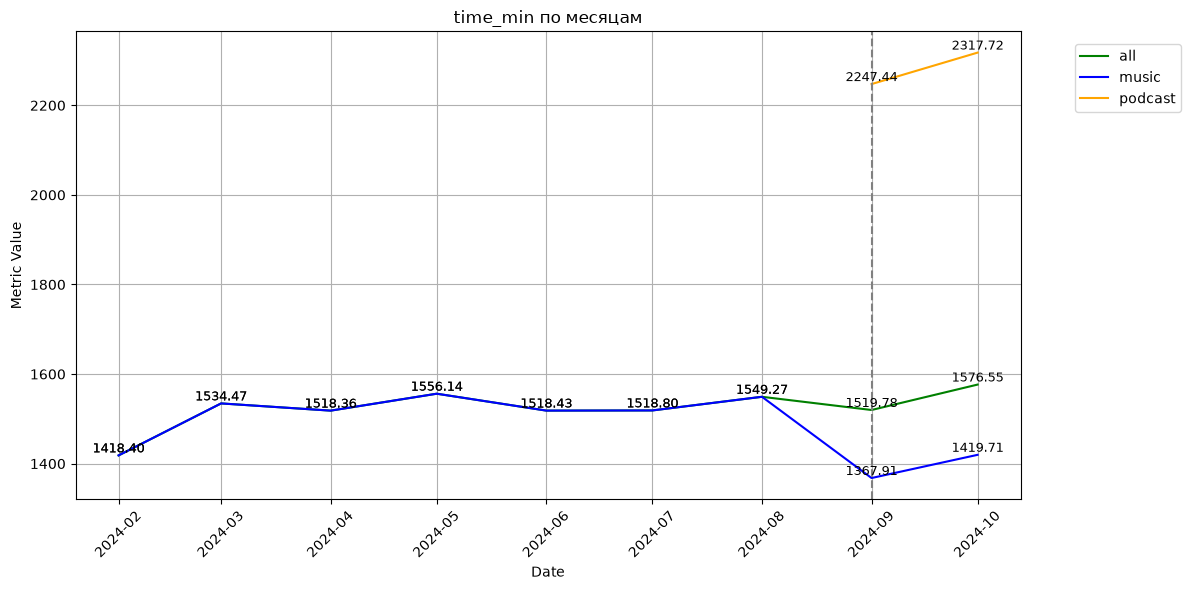

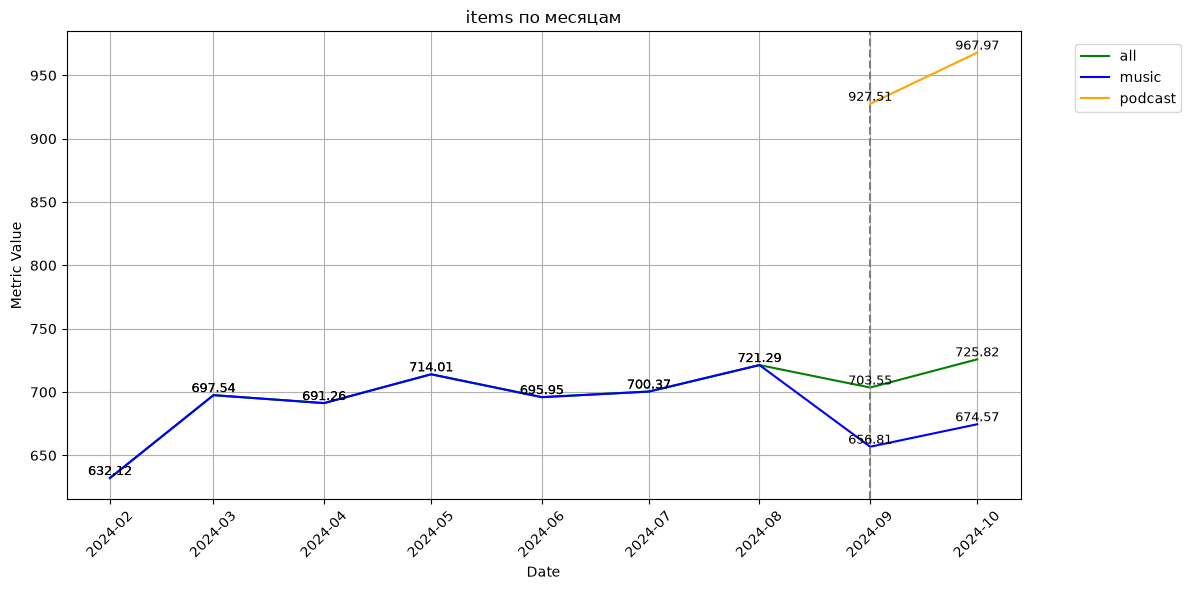

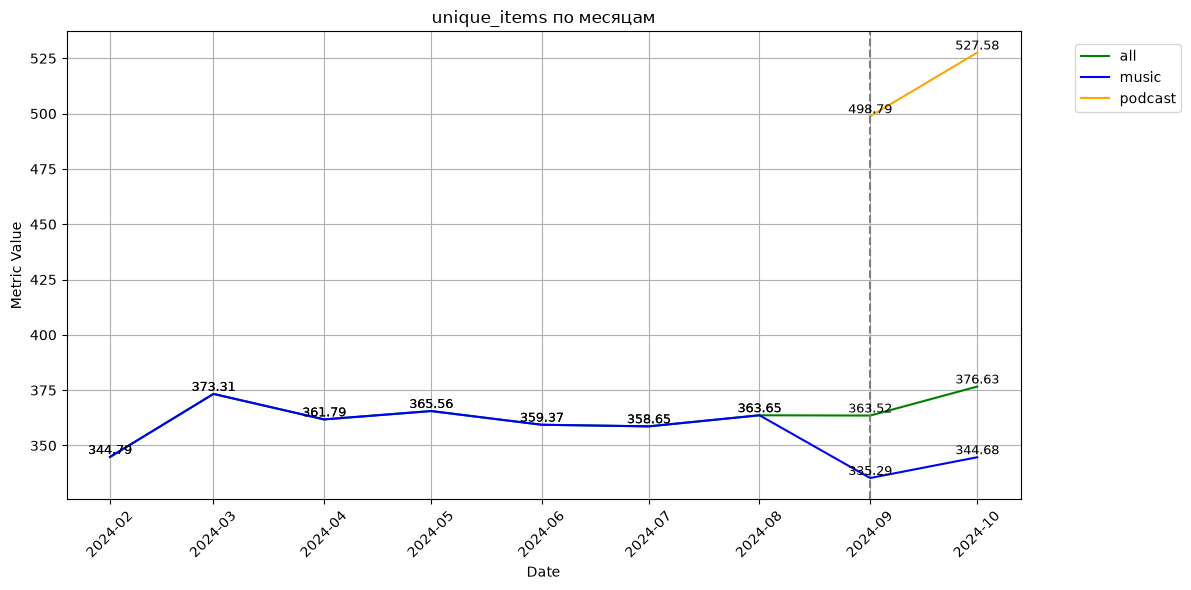

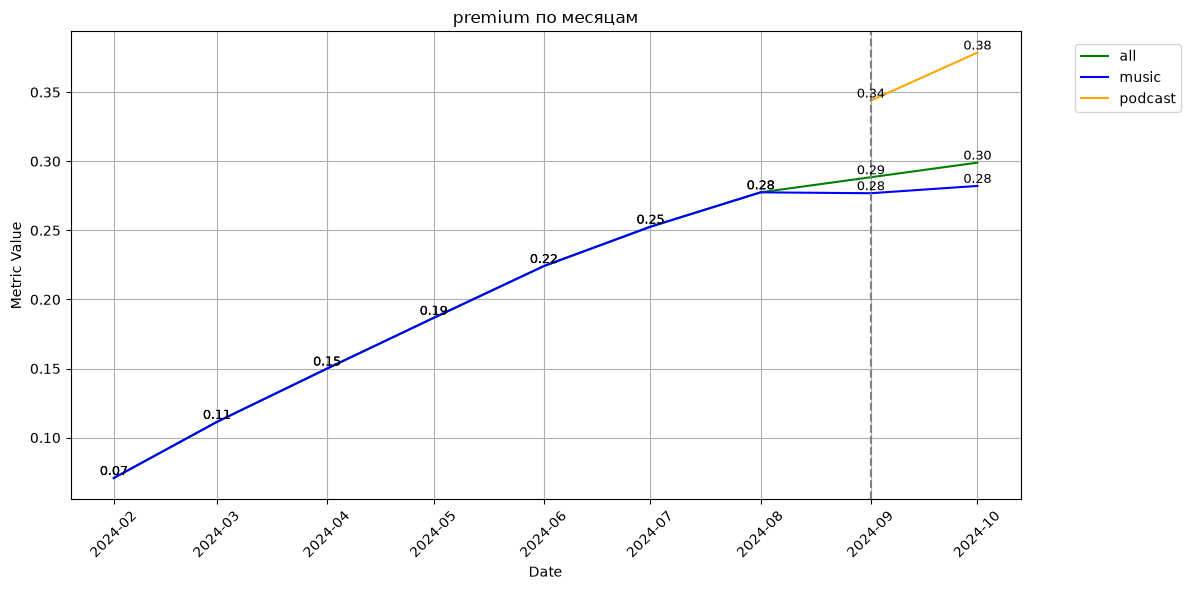

In [372]:
for metric in metrics:
    plot_df = month_metrics.pivot(index='month', columns='segment', values=metric).reset_index()
    plot_df = plot_df.rename(columns={'month': 'date'})
    get_several_lines_plot(plot_df, 'date', ['all', 'music', 'podcast'], title=f'{metric} по месяцам', vline=launch_date)

##### Доля дослушанных треков/эпизодов

In [376]:
df_music_logs['finished'] = df_music_logs['played_ratio_pct'] >= 100
df_music_logs[df_music_logs['finished'] == True]

,datetime,uid,item_id,played_ratio_pct,track_length_seconds,content_type,is_first_date,date,played_sec,podcast_interaction,is_podcast,week,month,finished
0,2024-01-13 10:00:00,468300,7400764,100,225,music,0.0,2024-01-13,225.0,False,False,2024-01-08,2024-01-01,True
1,2024-01-13 10:00:05,347600,3415205,100,250,music,0.0,2024-01-13,250.0,False,False,2024-01-08,2024-01-01,True
3,2024-01-13 10:00:15,243500,5283544,100,195,music,0.0,2024-01-13,195.0,False,False,2024-01-08,2024-01-01,True
4,2024-01-13 10:00:15,12700,8932363,100,245,music,0.0,2024-01-13,245.0,False,False,2024-01-08,2024-01-01,True
5,2024-01-13 10:00:20,992600,140621,100,270,music,0.0,2024-01-13,270.0,False,False,2024-01-08,2024-01-01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46384520,2024-11-09 08:13:05,658300,816570,100,120,music,0.0,2024-11-09,120.0,False,False,2024-11-04,2024-11-01,True
46384528,2024-11-09 08:13:15,960700,7430313,100,135,music,0.0,2024-11-09,135.0,False,False,2024-11-04,2024-11-01,True
46384531,2024-11-09 08:13:15,899900,4027449,100,240,music,0.0,2024-11-09,240.0,False,False,2024-11-04,2024-11-01,True
46384533,2024-11-09 08:13:15,645300,1172812,100,120,music,0.0,2024-11-09,120.0,False,False,2024-11-04,2024-11-01,True


In [377]:
finished_week = df_music_logs.groupby(['week', 'content_type'])['finished'].mean().unstack().reset_index()
finished_week['all'] = df_music_logs.groupby('week')['finished'].mean().values
finished_week = finished_week[(finished_week['week'] >= first_week) & (finished_week['week'] <= last_week)]
finished_week = finished_week.rename(columns={'week': 'date'})
finished_week.tail(12)

content_type,date,music,podcast,all
31,2024-08-12,0.535275,NaN,0.535275
32,2024-08-19,0.529583,NaN,0.529583
33,2024-08-26,0.534560,0.373196,0.534498
34,2024-09-02,0.539606,0.388614,0.539177
35,2024-09-09,0.528095,0.394283,0.527722
36,2024-09-16,0.530277,0.442507,0.529959
37,2024-09-23,0.531413,0.429455,0.531047
38,2024-09-30,0.528538,0.397627,0.528051
39,2024-10-07,0.525521,0.390538,0.525012
40,2024-10-14,0.529355,0.339277,0.528575


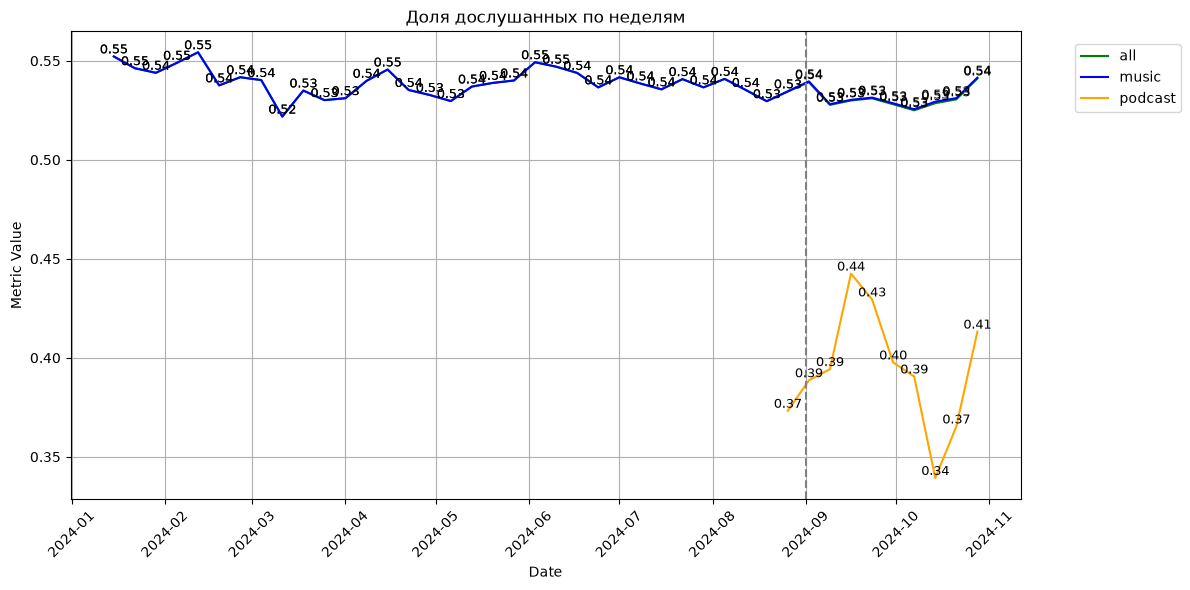

In [378]:
get_several_lines_plot(finished_week, 'date', ['all', 'music', 'podcast'], title='Доля дослушанных по неделям', vline=launch_date)

In [379]:
finished_month = df_music_logs.groupby(['month', 'content_type'])['finished'].mean().unstack().reset_index()
finished_month['all'] = df_music_logs.groupby('month')['finished'].mean().values
finished_month = finished_month[(finished_month['month'] >= first_month) & (finished_month['month'] <= last_month)]
finished_month = finished_month.rename(columns={'month': 'date'})
finished_month

content_type,date,music,podcast,all
1,2024-02-01,0.546809,NaN,0.546809
2,2024-03-01,0.531632,NaN,0.531632
3,2024-04-01,0.536392,NaN,0.536392
4,2024-05-01,0.537406,NaN,0.537406
5,2024-06-01,0.543282,NaN,0.543282
6,2024-07-01,0.538993,NaN,0.538993
7,2024-08-01,0.535547,NaN,0.535547
8,2024-09-01,0.530745,0.415721,0.530378
9,2024-10-01,0.531327,0.376989,0.530743


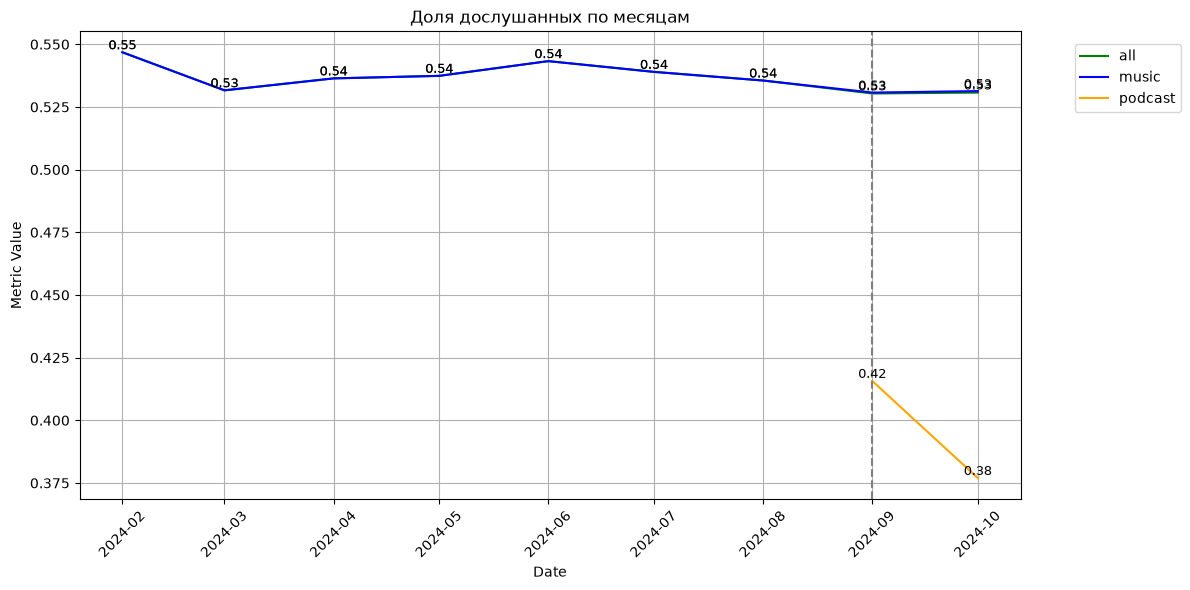

In [380]:
get_several_lines_plot(finished_month, 'date', ['all', 'music', 'podcast'], title='Доля дослушанных по месяцам', vline=launch_date)

##### Выводы по заданию 4

- Тренд: По времени прослушивания и числу item_id выраженного тренда нет: в месяц ~1420-1580 минут и ~630-725 прослушиваний на пользователя, в неделю около 400 минут и 190 треков. Колебания по месяцам частично объясняются разной длиной месяца (в феврале 29 дней, в октябре 31). 
Неуникальных item_id примерно в 2 раза больше, чем уникальных (~725 против ~375 в месяц): неуникальные показывают объём потребления, уникальные — ширину, то есть пользователи часто переслушивают одни и те же треки.

Доля премиум-подписчиков стабильно растёт: с 7% в феврале до 30% в октябре. Доля дослушанных у музыки стабильна, 53-55%.

- После запуска подкастов: В общих метриках ступенек нет. Единственное, что заметно — замедление роста доли премиума: прирост в июле +2,9 п.п., в августе +2,5, а в сентябре и октябре всего около +1. По времени это совпадает с запуском, но причинность отсюда не следует (это может быть и естественное насыщение), нужен отдельный анализ. Ещё после запуска расходятся линии all и music: самые активные пользователи уходят в сегмент podcast, поэтому у music метрики чуть ниже общих.

- Podcast vs music: Сегмент с подкастами заметно активнее: время на пользователя ~630-680 минут в неделю против ~400, item_id 250-275 против 175-195, уникальных 175-195 против 125-135, доля премиума 36-40% против 32%. Выводов о причине делать нельзя: скорее всего, подкасты пробуют те, кто и так много слушает и чаще платит, а не подкасты делают пользователей активнее.

- Типы контента: Подкасты дослушивают заметно реже музыки: 34-44% в неделю против 52-54%. По месяцам доля дослушанных подкастов падает с 41,6% в сентябре до 37,7% в октябре. Часть разницы объясняется тем, что эпизоды намного длиннее трека. Падение может говорить о спаде интереса после новизны, но пока это всего 2 точки.

#### 5. Метрики продукта (шаг 2)  — 2 балла

Рассчитайте и визуализируйте:
1) D1, D7, D30 retention по всем пользователям. Когорты агрегируйте по неделям т.к. из-за низкого числа новичков на дневном разрезе визуализации слишком шумные.
2) D30 retention для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами на промежутке до 30 дня. Когорты агрегируйте по неделям.
3) D7 retention для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами на промежутке до 7 дня. Когорты агрегируйте по месяцам.

Для наглядности будет полезно нарисовать на одном графике как посегментную, так и общую динамику (для этого можете достроить D7 retention для всех пользователей с помесячной агрегацией).

Сделайте выводы: 
- Есть ли выраженный тренд?
- Изменилась ли метрика после запуска подкастов?
- Отличается ли метрика сегмента, взаимодействовавшего с подкастами, от тех, кто слушал только музыку? (будьте аккуратны с выводами в этом пункте, мы не проверяем изменение на каузальность, поэтому не можем быть уверены где причина, а где следствие)

*За взаимодействие с подкастами давайте считать только прослушивание >= 30% или более 2х минут контента*

In [403]:
new_users = df_music_logs[df_music_logs['is_first_date'] == 1].groupby('uid')['date'].min().reset_index(name='first_date')
new_users['cohort_week'] = new_users['first_date'].dt.to_period('W').dt.start_time
new_users['cohort_month'] = new_users['first_date'].dt.to_period('M').dt.start_time
new_users.head()

,uid,first_date,cohort_week,cohort_month
0,200,2024-06-27,2024-06-24,2024-06-01
1,500,2024-10-02,2024-09-30,2024-10-01
2,1000,2024-05-23,2024-05-20,2024-05-01
3,1100,2024-03-16,2024-03-11,2024-03-01
4,1700,2024-03-04,2024-03-04,2024-03-01


In [404]:
new_users.groupby('cohort_week')['uid'].nunique()

cohort_week
2024-01-08     39
2024-01-15    171
2024-01-22    194
2024-01-29    188
2024-02-05    189
2024-02-12    141
2024-02-19    158
2024-02-26    146
2024-03-04    130
2024-03-11    138
2024-03-18    128
2024-03-25    115
2024-04-01    105
2024-04-08     98
2024-04-15    100
2024-04-22     92
2024-04-29     84
2024-05-06     74
2024-05-13     74
2024-05-20     93
2024-05-27    107
2024-06-03     87
2024-06-10     71
2024-06-17     80
2024-06-24     79
2024-07-01     89
2024-07-08    112
2024-07-15     70
2024-07-22    107
2024-07-29     92
2024-08-05    126
2024-08-12    115
2024-08-19    128
2024-08-26    136
2024-09-02    125
2024-09-09    141
2024-09-16    113
2024-09-23    117
2024-09-30    137
2024-10-07    121
2024-10-14    147
2024-10-21     86
2024-11-04      1
Name: uid, dtype: int64

In [405]:
ret = user_day[['date', 'uid', 'podcast_interaction']].merge(new_users, on='uid')
ret['day_n'] = (ret['date'] - ret['first_date']).dt.days
ret.head()

,date,uid,podcast_interaction,first_date,cohort_week,cohort_month,day_n
0,2024-01-13,81500,False,2024-01-13,2024-01-08,2024-01-01,0
1,2024-01-13,371300,False,2024-01-13,2024-01-08,2024-01-01,0
2,2024-01-13,375900,False,2024-01-13,2024-01-08,2024-01-01,0
3,2024-01-13,438500,False,2024-01-13,2024-01-08,2024-01-01,0
4,2024-01-13,627300,False,2024-01-13,2024-01-08,2024-01-01,0


In [406]:
last_date = user_day['date'].max()

def retention(df, cohort, n):
    size = df.groupby(cohort)['uid'].nunique()
    back = df[df['day_n'] == n].groupby(cohort)['uid'].nunique()
    return (back / size).fillna(0)

##### 1) D1, D7, D30 по всем пользователям (недельные когорты)

In [407]:
ret_week = pd.DataFrame({
    'd1': retention(ret, 'cohort_week', 1),
    'd7': retention(ret, 'cohort_week', 7),
    'd30': retention(ret, 'cohort_week', 30)
}).reset_index()
ret_week = ret_week.rename(columns={'cohort_week': 'date'})

In [446]:
ret_week = ret_week[ret_week['date'] >= first_week]
for n in [1, 7, 30]:
    not_full = ret_week['date'] + timedelta(days=6 + n) > last_date
    ret_week.loc[not_full, f'd{n}'] = None
ret_week.tail(10)

,date,d1,d7,d30
33,2024-08-26,0.632353,0.544118,0.551471
34,2024-09-02,0.728000,0.528000,0.512000
35,2024-09-09,0.652482,0.510638,0.482270
36,2024-09-16,0.716814,0.592920,0.513274
37,2024-09-23,0.769231,0.555556,0.606838
38,2024-09-30,0.656934,0.532847,0.474453
39,2024-10-07,0.710744,0.595041,NaN
40,2024-10-14,0.782313,0.632653,NaN
41,2024-10-21,0.755814,0.534884,NaN
42,2024-11-04,NaN,NaN,NaN


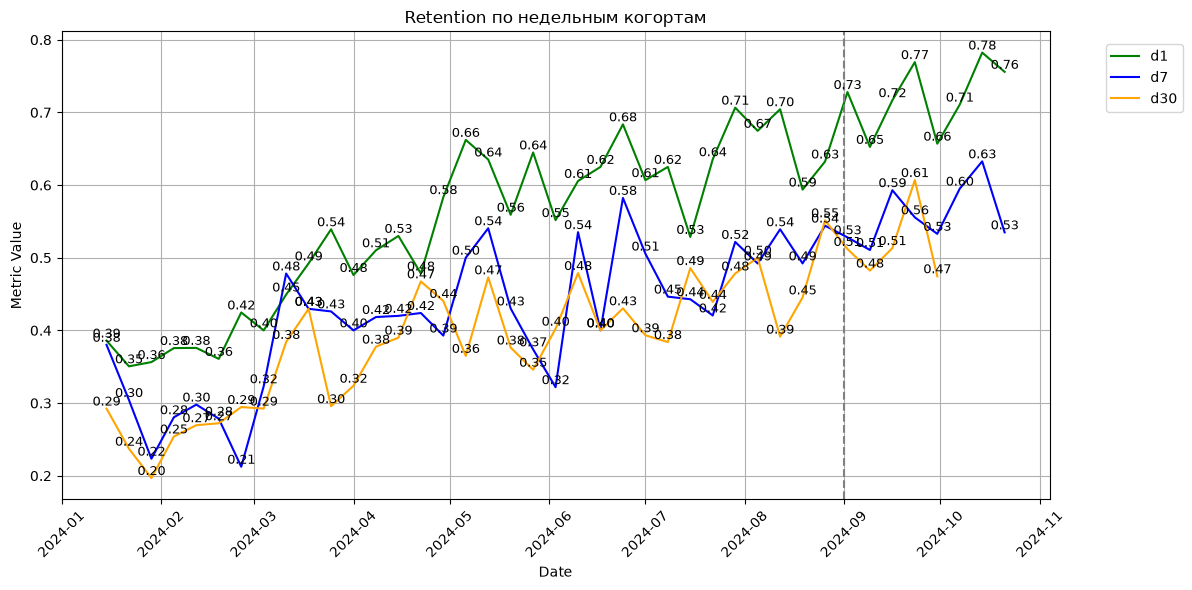

In [447]:
get_several_lines_plot(ret_week, 'date', ['d1', 'd7', 'd30'], title='Retention по недельным когортам', vline=launch_date)

##### 2) D30 по сегментам (взаимодействие с подкастами до 30 дня, недельные когорты)

In [448]:
podcast_30 = ret[(ret['day_n'] < 30) & ret['podcast_interaction']]['uid'].unique()
ret['podcast_30'] = ret['uid'].isin(podcast_30)
ret.groupby('podcast_30')['uid'].nunique()

podcast_30
False    4560
True      284
Name: uid, dtype: int64

In [449]:
d30_seg = pd.DataFrame({
    'all': retention(ret, 'cohort_week', 30),
    'music': retention(ret[~ret['podcast_30']], 'cohort_week', 30),
    'podcast': retention(ret[ret['podcast_30']], 'cohort_week', 30)
}).reset_index()
d30_seg = d30_seg.rename(columns={'cohort_week': 'date'})

In [450]:
d30_seg = d30_seg[(d30_seg['date'] >= first_week) & (d30_seg['date'] + timedelta(days=36) <= last_date)]
d30_seg.tail(10)

,date,all,music,podcast
29,2024-07-29,0.478261,0.478261,NaN
30,2024-08-05,0.500000,0.474576,0.875000
31,2024-08-12,0.391304,0.364486,0.750000
32,2024-08-19,0.445312,0.409091,0.666667
33,2024-08-26,0.551471,0.514563,0.666667
34,2024-09-02,0.512000,0.468750,0.655172
35,2024-09-09,0.482270,0.429825,0.703704
36,2024-09-16,0.513274,0.488372,0.592593
37,2024-09-23,0.606838,0.590909,0.655172
38,2024-09-30,0.474453,0.436893,0.588235


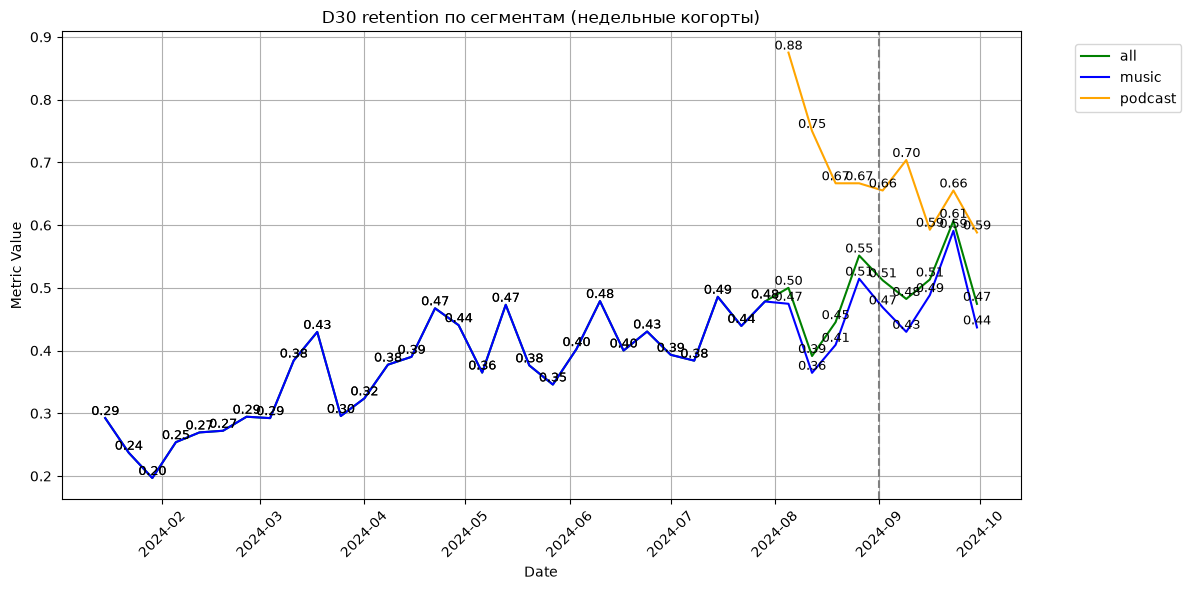

In [451]:
get_several_lines_plot(d30_seg, 'date', ['all', 'music', 'podcast'], title='D30 retention по сегментам (недельные когорты)', vline=launch_date)

In [ ]:
ret[ret['day_n'] == 0].groupby(['cohort_week', 'podcast_30'])['uid'].nunique().unstack().tail(10)

podcast_30,False,True
cohort_week,,
2024-08-26,103.0,33.0
2024-09-02,96.0,29.0
2024-09-09,114.0,27.0
2024-09-16,86.0,27.0
2024-09-23,88.0,29.0
2024-09-30,103.0,34.0
2024-10-07,97.0,24.0
2024-10-14,115.0,32.0
2024-10-21,71.0,15.0


##### 3) D7 по сегментам (взаимодействие с подкастами до 7 дня, месячные когорты)

In [453]:
podcast_7 = ret[(ret['day_n'] < 7) & ret['podcast_interaction']]['uid'].unique()
ret['podcast_7'] = ret['uid'].isin(podcast_7)
ret.groupby('podcast_7')['uid'].nunique()

podcast_7
False    4702
True      142
Name: uid, dtype: int64

In [454]:
d7_seg = pd.DataFrame({
    'all': retention(ret, 'cohort_month', 7),
    'music': retention(ret[~ret['podcast_7']], 'cohort_month', 7),
    'podcast': retention(ret[ret['podcast_7']], 'cohort_month', 7)
}).reset_index()
d7_seg = d7_seg.rename(columns={'cohort_month': 'date'})

In [455]:
month_end = d7_seg['date'] + pd.offsets.MonthEnd(0)
d7_seg = d7_seg[(d7_seg['date'] >= first_month) & (month_end + timedelta(days=7) <= last_date)]
d7_seg

,date,all,music,podcast
1,2024-02-01,0.271659,0.271659,NaN
2,2024-03-01,0.391608,0.391608,NaN
3,2024-04-01,0.402353,0.402353,NaN
4,2024-05-01,0.471545,0.471545,NaN
5,2024-06-01,0.437143,0.437143,NaN
6,2024-07-01,0.458234,0.458234,NaN
7,2024-08-01,0.518519,0.518657,0.500000
8,2024-09-01,0.543233,0.530568,0.621622
9,2024-10-01,0.579618,0.552826,0.750000


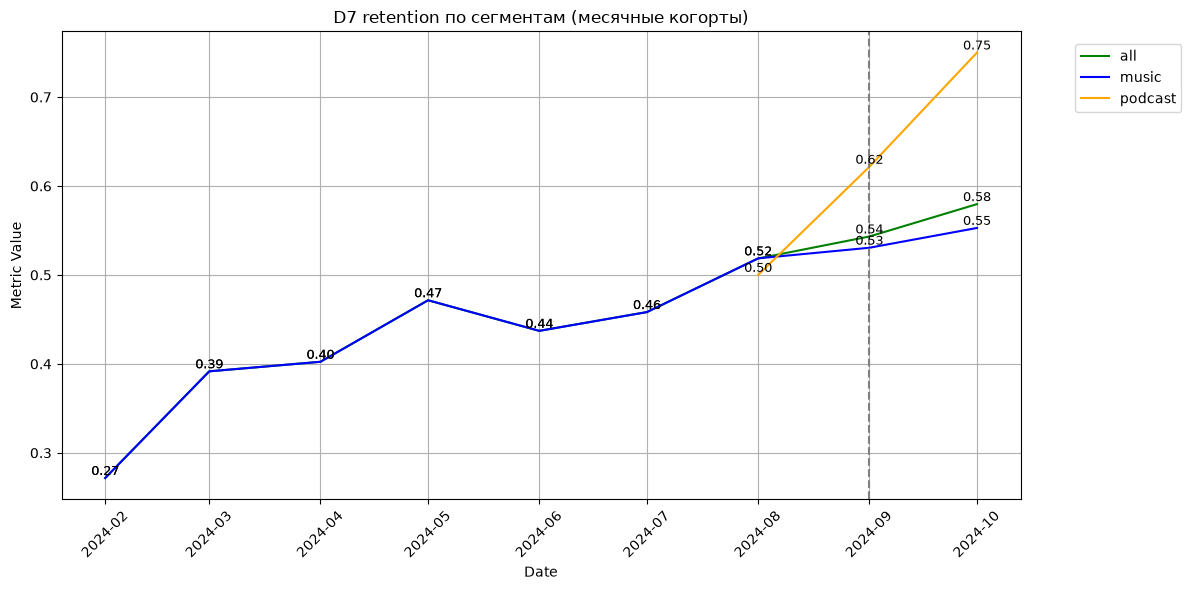

In [456]:
get_several_lines_plot(d7_seg, 'date', ['all', 'music', 'podcast'], title='D7 retention по сегментам (месячные когорты)', vline=launch_date)

##### Выводы по заданию 5

- Тренд: Retention растёт весь год. Месячный D7 по всем пользователям вырос с 0,27 в феврале до 0,58 в октябре. На недельных когортах осенью D1 0,63-0,78, D7 0,51-0,63, D30 0,47-0,61. Недельные точки шумные (в когортах 70-190 человек). 

- После запуска подкастов: Ступеньки нет, рост шёл и до запуска. Месячный D7 по всем пользователям: 0,52 в августе, 0,54 в сентябре, 0,58 в октябре — это продолжение прежнего тренда, эффект подкастов отсюда не отделить.

- Podcast vs music: У пользователей с подкастами retention выше. D30 после запуска 0,59-0,70 против 0,43-0,59 у music. Месячный D7: в августе 0,50 против 0,52 (у подкастов там очень мало людей), в сентябре 0,62 против 0,53, в октябре 0,75 против 0,55

Выводынеоднозначны: чтобы попасть в сегмент с подкастами, пользователь должен вернуться в продукт и послушать подкаст, поэтому retention там выше почти автоматически. Группа маленькая: 15-34 новичка в неделю для D30 и всего 142 человека за все месяцы для D7, первые точки D30 в августе (0,875, 0,75, 0,67) построены на единицах людей. И, возможно, подкасты просто пробуют те, кто и так более вовлечён

#### 6. Приоритизация метрик  — 2 балла

Составьте список всех метрик, которые были рассчитаны выше (не забудьте, что показатель, рассчитанный в разрезе сегмента — это отдельная метрика). Для простоты давайте ориентироваться только на недельную агрегацию.

1. Присвойте метрикам приоритеты P0-P3 по принципу (в этом пункте стройте приоритизацию на уровне всей компании):
   -  P0 — бизнес результат;
   -  P1 — метрики продукта, напрямую аффектящие бизнес-результат (retention, product as a habit);
   -  P2 — метрики, отражающие взаимодействие пользователя с продуктом (user experience, user engagement) / таргет-метрики отдельных команд продукта;
   -  P3 — метрики стримов / опыт пользователя в рамках работы отдельных команд.
2. Пересоберите приоритеты только для команды подкастов, если цель развития подкастов — рост пользователей с подпиской. Обратите внимание, что вам не нужно отказываться от метрик, рассчитанных по всем пользователям (без сегментов) или для сегмента Music (полезно понимать, не каннибализируем ли мы основной тип контента). Скорее всего приоритеты изменятся только для посегментных метрик.
4. Представьте, что цель внедрения подкастов поменялась — теперь команда в первую очередь хочет задрайвить вовлеченность в продукт. Пересоберите приоритеты при необходимости (в данном пункте могут измениться приоритеты для метрик, рассчитанных по всем пользователям).

Для каждого из пунктов дайте краткое обоснование, почему вы присвоили приоритеты именно так.

#### 6. Приоритизация метрик (недельная агрегация)

**Список метрик:** DAU, MAU, WAU, New Premium Subs, Podcast Penetration, Avg Listen Time (all / podcast / music_only), Items per User, Unique Items per User, Premium Share, Completion Rate (music / podcast), D1/D7/D30 Retention (all / podcast / music_only).

---

**1. Приоритеты на уровне компании**

| Метрика | Приоритет | Обоснование |
|---|---|---|
| New Premium Subs | **P0** | Прямой бизнес-результат — выручка от подписки |
| MAU, Premium Share | **P0/P1** | MAU — масштаб бизнеса; Premium Share — монетизация базы |
| D7/D30 Retention | **P1** | Удержание напрямую влияет на LTV и выручку |
| DAU, WAU, User Stickiness | **P1** | Опер прокси здоровья продукта |
| Avg Listen Time, Items per User | **P2** | Вовлечённость в продукт, идёт до и кореллируети с монетизацией |
| Podcast Penetration | **P2** | Трекинг нового направления, пока не core rev |
| Completion Rate | **P2/P3** | Качество контента и CX |
| Посегментные метрики podcast vs music | **P3** | Аналитика для внутренних команд |

---

**2. Цель команды подкастов — рост подписчиков**

| Метрика | Новый приоритет | Обоснование |
|---|---|---|
| Podcast Penetration | **P0** | Главный индикатор адопшн нового раздела |
| Premium Share | **P0** | Целевой сегмент для конверсии в подписку |
| New Premium Subs | **P0** | Итоговая метрика команды |
| D30 Retention (podcast) | **P1** | Удержание подписчиков, пришедших через подкасты |
| Completion Rate (podcast) | **P1** | Качество контента, влияет на конверсию |
| Avg Listen Time (podcast) | **P2** | Вовлечённость в формат |
| Метрики music_only / all users | **P2** | Контроль каннибализации основного продукта |
| DAU/MAU общие | **P2** | Контекст, но не primary KPI команды |

---

**3. Цель — вовлечённость (engagement)**

| Метрика | Новый приоритет | Обоснование |
|---|---|---|
| Avg Listen Time | **P0** | Прямая метрика вовлечённости |
| Items / Unique Items per User | **P0** | Глубина и ширина потребления |
| D7 Retention (all) | **P1** | Удержание продукта |
| Completion Rate | **P1** | Пользователь дослушивает — выше вовлечённость |
| Podcast Penetration | **P1** | Новый формат как драйвер времени в приложении |
| Avg Listen Time (podcast vs music) | **P2** | Сравнение форматов |
| New Premium Subs | **P2** | Важно, но вторично при увеличении вовлечённости |
| WAU/DAU | **P2** | опер мониторинг |


#### Использование ИИ

- Задания: Для стилизации, выводов в 3,4,5 и шаблона таблицы важности 
- Модель: Claude Opus 5.5